# 2026.10.27(화) 19h40~ 음성 모델의 이해 · 5강 — 데이터와 정답 준비 | 실습

이 노트북에서는 **제공된 한국어 WAV 5개로 기본 이론 실습을 먼저 진행**합니다. 이후 각 교시의 **[자율실습]**에서 본인이 녹음한 음성 3개에 같은 원리를 적용합니다.

- **이론 교재:** `05_data_labels_theory.html` (웹브라우저에서 열기)
- **필수 제공 자료:** `data/speech_manifest.json`, `data/speech/` 아래 한국어 WAV 5개
- **개인 실습 자료:** `data/my_speech/my_001.wav` ~ `my_003.wav` (학생이 제작)
- **진행 순서:** 제공 데이터로 1교시 → 자기 음성 1-S → 제공 데이터로 2교시 → 2-S → 3교시 → 3-S → 3-T(선택) → 4교시 → 4-S → 4-T → 4-U(선택)
- **표기:** [기본 실습]은 모두 실행합니다. [직접 변경]은 안내된 값만 수정합니다. [자율실습]은 학생의 파일을 직접 준비합니다.

각 교시는 *개념 → 제공 데이터 실습 → 관찰 기록 → 내 데이터 자율 적용*으로 마칩니다. 커널을 다시 시작했다면 위에서부터 실행하세요.
**번호 원칙:** HTML과 노트북의 실습 번호·제목은 동일합니다. 번호가 없는 ‘개념’은 설명이고, 실습 번호는 실행할 코드 묶음을 가리킵니다.


## HTML · 노트북 공통 실습 목차

번호가 같은 항목끼리 연결됩니다. 링크는 HTML 설명으로 이동합니다. 실행은 아래 코드 셀에서 진행하세요.

| 번호 | 실습 제목 · 진행 방식 |
|---|---|
| 준비 | [준비 · 경로와 실행 환경 [기본 실습]](05_data_labels_theory.html#practice-0) |
| 1-1 | [실습 1-1 · Manifest 읽기·검사 도구 [기본 실습]](05_data_labels_theory.html#practice-1-1) |
| 1-2 | [실습 1-2 · 실제 정답 JSON 열어 보기 [기본 실습]](05_data_labels_theory.html#practice-1-2) |
| 1-3 | [실습 1-3 · WAV를 듣고 정답 확인 [직접 변경]](05_data_labels_theory.html#practice-1-3) |
| 1-4 | [실습 1-4 · 줄 순서 연결과 ID 연결 비교 [기본 실습]](05_data_labels_theory.html#practice-1-4) |
| 1-5 | [실습 1-5 · 잘못된 Manifest 찾기 [직접 변경]](05_data_labels_theory.html#practice-1-5) |
| 1-6 | [실습 1-6 · 구조 검사가 전사 내용까지 검사할까? [기본 실습]](05_data_labels_theory.html#practice-1-6) |
| 1-S | [자율실습 1-S · 직접 녹음하고 내 정답 JSON 만들기](05_data_labels_theory.html#practice-1-S) |
| 2-1 | [실습 2-1 · 가상 화자 A·B·C 분할하기 [기본 실습]](05_data_labels_theory.html#practice-2-1) |
| 2-2 | [실습 2-2 · `report_split()`으로 겹치는 화자 찾기 [기본 실습]](05_data_labels_theory.html#practice-2-2) |
| 2-3 | [실습 2-3 · 분할 오류를 의도적으로 만들기 [직접 변경]](05_data_labels_theory.html#practice-2-3) |
| 2-4 | [실습 2-4 · 동일 화자를 한 그룹으로 다시 모으기 [기본 실습]](05_data_labels_theory.html#practice-2-4) |
| 2-S | [자율실습 2-S · 내 음성의 화자 정보와 평가 가능성 확인](05_data_labels_theory.html#practice-2-S) |
| 3-1 | [실습 3-1 · 작은 숫자로 패딩과 마스크 원리 관찰 [기본 실습]](05_data_labels_theory.html#practice-3-1) |
| 3-2 | [실습 3-2 · 제공 WAV → Log-Mel 특징 변환 [기본 실습]](05_data_labels_theory.html#practice-3-2) |
| 3-3 | [실습 3-3 · 실제 음성 특징 배치·마스크 시각화 [기본 실습]](05_data_labels_theory.html#practice-3-3) |
| 3-4 | [실습 3-4 · 선택한 파일 조합에 따른 패딩 비교 [직접 변경]](05_data_labels_theory.html#practice-3-4) |
| 3-5 | [실습 3-5 · 마스크 적용 평균이 필요한 이유 [기본 실습]](05_data_labels_theory.html#practice-3-5) |
| 3-6 | [실습 3-6 · 패딩을 2·4·6칸으로 바꿀 때 평균 [직접 변경]](05_data_labels_theory.html#practice-3-6) |
| 3-S | [자율실습 3-S · 내 음성 품질 관찰과 X 배치 [직접 작성]](05_data_labels_theory.html#practice-3-S) |
| 3-T | [자율실습 3-T · 녹음 품질이 좋지 않은 사례 비교 [선택]](05_data_labels_theory.html#practice-3-T) |
| 4-1 | [실습 4-1 · 어절 사전, 미등록 토큰 `<unk>` [기본 실습]](05_data_labels_theory.html#practice-4-1) |
| 4-2 | [실습 4-2 · 문장별 토큰 ID 바꾸어 보기 [직접 변경]](05_data_labels_theory.html#practice-4-2) |
| 4-3 | [실습 4-3 · 미등록 어절을 남기는 이유 [기본 실습]](05_data_labels_theory.html#practice-4-3) |
| 4-4 | [실습 4-4 · 정답 토큰 배치·마스크 [기본 실습]](05_data_labels_theory.html#practice-4-4) |
| 4-5 | [실습 4-5 · 제공 음성 3개의 정답 y 만들기 [기본 실습]](05_data_labels_theory.html#practice-4-5) |
| 4-6 | [실습 4-6 · ID·정답·마스크 검증 [기본 실습]](05_data_labels_theory.html#practice-4-6) |
| 4-7 | [실습 4-7 · 결과와 처리 조건을 함께 저장하기 [선택]](05_data_labels_theory.html#practice-4-7) |
| 4-8 | [실습 4-8 · 저장한 결과를 다시 읽어 확인하기 [선택]](05_data_labels_theory.html#practice-4-8) |
| 4-S | [자율실습 4-S · 내 목소리의 정답 y와 최종 배치 검증](05_data_labels_theory.html#practice-4-S) |
| 4-T | [자율실습 4-T · 정답 연결이 잘못되었을 때 찾아내기 [직접 변경]](05_data_labels_theory.html#practice-4-T) |
| 4-U | [자율실습 4-U · 6강에서 살펴볼 결과 저장 [선택]](05_data_labels_theory.html#practice-4-U) |


## 준비 · 경로와 실행 환경 [기본 실습]

**왜 하나요?** 제공된 파일과 라이브러리가 준비되었는지 먼저 확인합니다. `False`가 나타나면 ZIP을 풀고 노트북이 있는 폴더에서 실행하세요.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-0).


In [1]:
# 목적: 입력과 출력에 필요한 경로·도구를 준비하고 확인합니다.
# 입력: data 폴더의 한국어 WAV와 정답 목록 / 출력: 이후 셀에서 쓸 도구와 경로
# 음성·정답 처리 목적에 맞춰 라이브러리를 준비하는 셀입니다.
# 실행 준비: 필요한 기능을 불러옵니다.
import json
# 파일 내용이 기록된 원본과 같은지 SHA-256으로 확인할 때 사용합니다.
import hashlib
from pathlib import Path
from math import gcd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy.io import wavfile
# stft는 시간별 주파수 분석, resample_poly는 샘플링 주파수 변환에 사용합니다.
from scipy.signal import stft, resample_poly
from IPython.display import Audio, display

# 사용할 수 있는 한글 글꼴을 찾아 그래프에 적용합니다.
available_fonts = {font.name for font in fm.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in available_fonts:
        plt.rcParams["font.family"] = name
        break
# 일부 한글 글꼴에서 음수 기호가 네모로 보이는 현상을 방지합니다.
plt.rcParams["axes.unicode_minus"] = False

# 상대 경로는 현재 작업 폴더 기준입니다. 이 두 줄만으로 폴더가 생기지는 않습니다.
DATA = Path("data")
RESULTS = Path("results")
print("현재 작업 폴더:", Path.cwd())
print("정답 목록 존재:", (DATA / "speech_manifest.json").is_file())
print("준비 완료: 아직 결과 파일은 저장하지 않았습니다.")


정답 목록 존재: True
준비 완료: 아직 결과 파일은 저장하지 않았습니다.


---
## 1교시 · 실제 WAV 파일과 한국어 정답을 연결하기

**핵심 질문:** 음성 5개 중 특정 ID가 가리키는 파일과 정답 문장이 올바르게 연결되었을까요?

**이번 교시의 결과:** 제공 자료의 Manifest를 검사하고, 음성을 들어 정답을 확인한 다음, 자신의 음성 3개에 대한 Manifest를 작성합니다.

### 실습 1-1 · Manifest 읽기·검사 도구 [기본 실습]

이론 교재의 **개념 · ‘정답’과 ‘목록’은 무엇인가?**와 **실습 1-1**에서 `id`, `file`, `reference`, `speaker_id`, SHA-256의 역할을 읽으세요. 다음 코드는 WAV 전처리·Manifest 검사를 위한 도구를 정의합니다. 함수의 모든 문법을 외우기보다 *어떤 오류를 발견하는가*에 주목하세요.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-1-1).


In [2]:
# 목적: ID 순서에 따른 음성–정답 연결을 확인합니다.
# 용도: 목록 읽기 → WAV 읽기 → 목록 검사에 사용할 함수를 정의합니다.
# 이 셀 자체는 학습이나 음성 인식을 수행하지 않습니다.
def read_json(path):
    # 한국어 정답이 깨지지 않도록 UTF-8로 읽습니다.
    # JSON 텍스트를 파이썬 자료형으로 변환합니다.
    # 이번 정답 목록은 '리스트 안에 딕셔너리 5개'가 있는 구조입니다.
    return json.loads(Path(path).read_text(encoding="utf-8"))


def load_audio(path):
    # sr: 샘플링 주파수 — 1초에 저장된 샘플 수
    # samples: 실제 음성 파형을 구성하는 숫자 배열
    sr, samples = wavfile.read(path)

    # 이번 실습은 PCM16 형식의 WAV를 사용합니다.
    # PCM16은 각 샘플을 16비트 정수(int16)로 저장합니다.
    #
    # 일반적인 배열 모양:
    # 모노     → (샘플 수,)        : 1차원
    # 스테레오 → (샘플 수, 채널 수) : 2차원
    #
    # 형식이 다르거나 데이터가 비어 있으면 처리를 중단합니다.
    # 단, 아래 ndim 검사는 2차원 배열의 채널 수가 정확히 2인지까지
    # 확인하는 것은 아닙니다.
    if samples.dtype != np.int16 or samples.ndim not in (1, 2) or samples.size == 0:
        raise ValueError(f"{path}: 비어 있지 않은 PCM16 모노/스테레오 WAV가 필요합니다.")

    # PCM16의 값 범위: -32768 ~ 32767
    # 실수형으로 바꾸고 32768로 나누어 약 -1 ~ 1 범위로 맞춥니다.
    # 정확히는 -1.0 이상, 1.0 미만입니다.
    #
    # 파일마다 최대 음량을 같게 만드는 처리는 아닙니다.
    # 정수로 저장된 진폭을 일정한 기준으로 실수 표현으로 바꾸는 것입니다.
    # 샘플링 주파수와 채널 수는 변경하지 않습니다.
    return int(sr), samples.astype(np.float32) / 32768.0


def check_manifest(rows, data_dir, expected_count=5):
    # manifest는 '음성 파일의 위치와 정답 문장을 연결한 목록'입니다.
    # 이 함수는 목록 구조, 중복, 파일 존재 여부, 파일 내용 변경을 검사합니다.
    # 음성을 듣고 정답 문장의 내용이 맞는지 판단하지는 않습니다.

    # 5개라는 개수는 음성 처리의 필수 조건이 아니라 이번 실습의 조건입니다.
    if not isinstance(rows, list) or len(rows) != expected_count:
        raise ValueError(f"이 실습에는 {expected_count}개 항목의 목록이 필요합니다.")

    ids = []
    files = []
    missing_files = []

    for number, row in enumerate(rows, start=1):
        if not isinstance(row, dict):
            raise ValueError(f"{number}번째 항목은 딕셔너리여야 합니다.")

        # 자료 한 건을 연결하는 데 필요한 세 가지 정보를 확인합니다.
        # id        : 음성 자료의 고유 번호
        # file      : data_dir 기준의 음성 파일 경로
        # reference : 음성에서 실제로 말한 내용을 적은 정답 문장
        #
        # 항목이 없거나, 문자열이 아니거나, 공백만 들어 있으면 오류입니다.
        for key in ("id", "file", "reference"):
            if not isinstance(row.get(key), str) or not row[key].strip():
                raise ValueError(f"{number}번째 항목의 {key}가 없거나 비어 있습니다.")

        relative = Path(row["file"])

        # 목록에는 'speech/파일명.wav'처럼 data_dir 기준 경로를 사용합니다.
        # 절대 경로나 상위 폴더로 이동하는 '..'는 허용하지 않습니다.
        if relative.is_absolute() or ".." in relative.parts:
            raise ValueError(f"허용하지 않는 상대 경로: {relative}")

        ids.append(row["id"])
        files.append(row["file"])

        # 예: data_dir가 'data', relative가 'speech/a.wav'이면
        # 실제 확인하는 경로는 'data/speech/a.wav'입니다.
        # 목록에 이름만 적혀 있고 실제 파일이 없는 경우를 찾습니다.
        if not (data_dir / relative).is_file():
            missing_files.append(str(data_dir / relative))

    # 같은 ID가 여러 번 있으면 어떤 자료의 정답인지 모호해집니다.
    # 특히 ID를 사전의 키로 사용하면 이전 값이 덮어써질 수 있습니다.
    if len(set(ids)) != len(ids):
        raise ValueError("중복 ID가 있습니다. 원본 목록을 확인하세요.")

    # ID가 서로 달라도 같은 파일 경로를 중복 등록했는지 확인합니다.
    # 여기서는 경로 문자열의 중복을 검사합니다.
    # 이름이 다른 두 파일의 내용이 같은지까지 비교하는 검사는 아닙니다.
    if len(set(files)) != len(files):
        raise ValueError("같은 파일이 중복 등록되었습니다.")

    # 누락된 파일이 여러 개면 한 번에 알려 줍니다.
    if missing_files:
        raise FileNotFoundError("누락된 WAV: " + ", ".join(missing_files))

    for row in rows:
        # 목록에 SHA-256 값이 기록된 항목만 파일 내용까지 확인합니다.
        # SHA-256은 파일의 전체 바이트로 계산하는 '내용 확인용 지문'입니다.
        if "sha256" in row:
            # [한 줄씩 읽기] 안쪽부터 바깥쪽 순서로 실행됩니다. (아래 숫자는 직접 실행해 확인한 값)
            #  ① (data_dir / row["file"])  : 파일 경로. 예: data/speech/xxx.wav
            #  ② .read_bytes()             : 파일 전체를 '바이트(0~255 숫자의 나열)'로 읽음.
            #                                파형 숫자로 해석하기 전의 원본 그대로입니다. (첫 항목 WAV: 156,750바이트)
            #  ③ hashlib.sha256(바이트)     : 그 바이트 전체로 SHA-256 계산을 수행.
            #                                결과는 아직 '해시 객체'이고 글자가 아닙니다.
            #  ④ .hexdigest()              : 계산 결과(32바이트)를 16진수 '글자'로 바꿔 꺼냄.
            #                                0~9, a~f 문자 64개짜리 문자열 → 목록의 "sha256" 값과 비교할 수 있음.
            #                                예: '7c4faf86296a0d83b611f41665ddc3f6…' (64자)
            #                                ('hex' = 16진수, 'digest' = 요약값이라는 뜻)
            # 성질: 같은 내용이면 항상 같은 값이고, 파일이 1바이트만 바뀌어도 값이 완전히 달라집니다.
            #       (끝 1비트만 바꿔 보니 '7c4faf86…' → '2f0fe2c7…'). 반대로 값만으로는 원본 파일을 복원할 수 없습니다.
            # 주의: 해시는 '내용이 같은가'만 알려 줍니다. 발화와 정답 문장이 맞는지, 음질이 좋은지는 알려 주지 않습니다.
            actual_hash = hashlib.sha256(
                (data_dir / row["file"]).read_bytes()
            ).hexdigest()

            # 파일명이 같아도 내용이 바뀌면 해시가 달라집니다.
            # 예: 영어 WAV를 한국어 WAV로 교체하고
            # 이전 영어 파일의 해시가 담긴 목록을 그대로 사용한 경우
            if actual_hash != row["sha256"]:
                raise ValueError(
                    f"{row['id']}: 파일 내용의 SHA-256이 목록과 다릅니다."
                )

    # 모든 검사 항목을 통과했다는 의미입니다.
    # WAV의 PCM16 형식은 load_audio()에서 별도로 검사하며,
    # 실제 발화와 정답 문장의 일치는 청취 등으로 따로 확인해야 합니다.
    return True


# 함수 정의가 끝났다는 뜻이며, 아직 실제 파일을 검사한 것은 아닙니다.
print("제공 함수 준비 완료")

제공 함수 준비 완료


### 실습 1-2 · 실제 정답 JSON 열어 보기 [기본 실습]

아래 결과에서 **ID, 파일 경로, 정답 문장, 음성 그룹**을 찾아보세요. SHA-256은 파일 내용 변경을 확인하지만, 정답 문장의 정확성을 판단하지는 못합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-1-2).


In [3]:
# 목적: ID 순서에 따른 음성–정답 연결을 확인합니다.
# 용도: 파일과 정답 목록의 연결 상태를 점검합니다.
# WAV 형식 검사는 load_audio(), 발화 내용 확인은 청취 검수로 이어집니다.
# 음성 파일의 위치와 한국어 정답이 기록된 목록의 경로입니다.
# DATA가 Path("data")이면 data/speech_manifest.json을 가리킵니다.
manifest_path = DATA / "speech_manifest.json"

# 정답 목록이 없으면 음성과 정답을 연결할 수 없으므로 중단합니다.
# 상대 경로의 기준은 현재 작업 폴더입니다.
if not manifest_path.is_file():
    raise FileNotFoundError("노트북 옆 data 폴더에 한국어 speech_manifest.json을 넣으세요.")

# JSON 파일을 읽어 파이썬 리스트로 변환합니다.
# items의 각 항목에는 ID, 파일 경로, 정답 문장 등이 들어 있습니다.
# 이 단계에서는 WAV의 음성 데이터를 읽지 않습니다.
items = read_json(manifest_path)

# 목록 구조, 필수 항목, ID·파일 경로 중복, 파일 누락,
# 기록된 SHA-256과 실제 파일 내용의 일치 여부를 검사합니다.
# 문제가 있으면 오류가 발생하며 아래 출력으로 진행하지 않습니다.
check_manifest(items, DATA)

# 여기까지 실행되었다면 위 검사를 통과한 것입니다.
# 실제 발화와 정답 문장이 일치한다는 뜻은 아닙니다.
print("목록 검사 통과 / 항목 수:", len(items))

# speaker_id를 중복 없이 모아 음성 그룹의 종류를 확인합니다.
# 이번 한국어 자료는 같은 TTS 설정으로 만든 ko_tts_01 그룹입니다.
# 파일이 5개여도 음성 그룹은 하나일 수 있습니다.
# speaker_id 항목이 없는 경우에는 "미기록"으로 표시합니다.
print("음성 그룹:", sorted({str(row.get("speaker_id", "미기록")) for row in items}))

# 첫 번째 자료의 ID, 파일 위치, 정답 등을 눈으로 확인합니다.
print("첫 번째 항목:")

# 파이썬 딕셔너리를 읽기 편한 JSON 문자열로 바꾸어 화면에 출력합니다.
# ensure_ascii=False: 한국어를 한글 그대로 표시합니다.
# indent=2: 항목을 줄바꿈하고 두 칸씩 들여씁니다.
# 파일로 저장하거나 원본 목록을 수정하는 작업은 아닙니다.
print(json.dumps(items[0], ensure_ascii=False, indent=2))

목록 검사 통과 / 항목 수: 5
음성 그룹: ['ko_tts_01']
첫 번째 항목:
{
  "id": "1272-128104-0001",
  "file": "speech/1272-128104-0001.wav",
  "reference": "안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.",
  "speaker_id": "ko_tts_01",
  "language": "ko",
  "source": "Korean synthetic speech generated with gTTS / Google Translate TTS",
  "sha256": "7c4faf86296a0d83b611f41665ddc3f630cc7f05775f5eec0fd976a8a08e3f85",
  "sample_rate": 16000,
  "channels": 1,
  "duration_seconds": 4.896
}


### 실습 1-3 · WAV를 듣고 정답 확인 [직접 변경]

`CHOSEN_INDEX`를 `0`, `2`, `4`로 바꾸어 최소 3개의 음성을 들어보세요. 실제로 말한 내용과 `reference`가 일치하는지, 시간축과 녹음 길이가 어떻게 달라지는지 관찰합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-1-3).


ID: 1272-128104-0001
정답: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.
샘플링 주파수: 16000 Hz / 길이: 4.896초


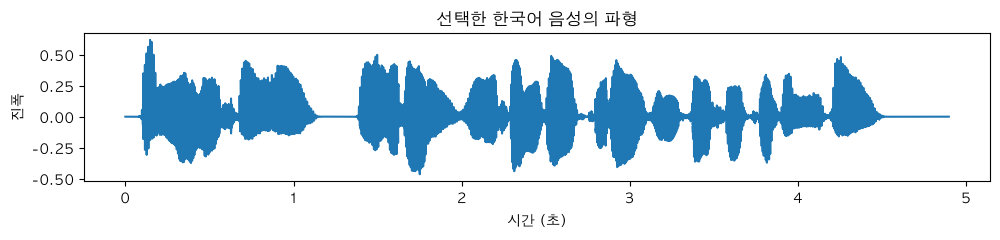

In [4]:
# 목적: ID 순서에 따른 음성–정답 연결을 확인합니다.
# 선택한 자료의 ID·정답·길이·소리를 함께 확인하는 청취 검수 시연입니다.
CHOSEN_INDEX = 0  # 학생이 바꿀 값: 0~4 중 하나
chosen = items[CHOSEN_INDEX]
# 목록의 파일 위치를 기준으로 읽어야 화면의 정답과 같은 자료를 확인할 수 있습니다.
sr, sound = load_audio(DATA / chosen["file"])
print("ID:", chosen["id"])
print("정답:", chosen["reference"])
print(f"샘플링 주파수: {sr} Hz / 길이: {len(sound) / sr:.3f}초")
# IPython Audio의 스테레오 입력은 (채널, 시간) 순서가 필요합니다.
audio_for_display = sound.T if sound.ndim == 2 else sound
# 원래 샘플링 주파수로 재생합니다. rate를 바꾸면 재생 속도와 음높이가 달라집니다.
# normalize=False는 재생할 때 파일마다 최대 음량을 자동으로 맞추지 않는 설정입니다.
display(Audio(audio_for_display, rate=sr, normalize=False))
plt.figure(figsize=(10, 2.5))
# 샘플 번호를 초 단위 시간으로 바꿉니다. 샘플 번호 / 초당 샘플 수 = 시간(초).
plt.plot(np.arange(len(sound)) / sr, sound)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("선택한 한국어 음성의 파형")
plt.tight_layout()
plt.show()


### 실습 1-4 · 줄 순서 연결과 ID 연결 비교 [기본 실습]

정답 목록만 거꾸로 뒤집어 **위치만으로 연결하면 잘못되는 건수**를 확인합니다. 반면 ID를 기준으로 조회하면 정답이 그대로 연결됩니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-1-4).


In [5]:
# 목적: 목록의 줄 순서와 자료의 ID가 서로 다른 기준임을 비교합니다.
# 원본 items를 바꾸지 않고 정답을 꺼내는 목록의 순서만 뒤집습니다.
# 시연: 파일 목록은 그대로 두고, 정답 목록만 역순으로 만듭니다.
reversed_rows = list(reversed(items))
wrong_matches = 0
for audio_row, text_row in zip(items, reversed_rows):
    # 같은 위치의 두 항목이 실제로 같은 자료인지 ID로 판별합니다.
    is_same = audio_row["id"] == text_row["id"]
    if not is_same:
        wrong_matches += 1
    print(audio_row["id"], "↔", text_row["id"], "같은 자료:", is_same)
print("순서로 연결했을 때 잘못 붙은 개수:", wrong_matches)

# 고유 ID를 열쇠로 하는 사전을 만듭니다.
# ID → 정답의 대응표를 만듭니다. ID 중복은 앞서 검사한 상태여야 합니다.
# 중복 키가 있으면 나중 정답이 앞의 정답을 덮어쓸 수 있습니다.
references = {}
for row in reversed_rows:
    references[row["id"]] = row["reference"]

print("\nID로 다시 연결한 결과")
for row in items:
    # 순서가 아닌 고유 ID로 찾으므로 정답 목록이 역순이어도 올바르게 연결됩니다.
    print(row["id"], "→", references[row["id"]])


1272-128104-0001 ↔ 1272-128104-0014 같은 자료: False
1272-128104-0006 ↔ 1272-128104-0012 같은 자료: False
1272-128104-0008 ↔ 1272-128104-0008 같은 자료: True
1272-128104-0012 ↔ 1272-128104-0006 같은 자료: False
1272-128104-0014 ↔ 1272-128104-0001 같은 자료: False
순서로 연결했을 때 잘못 붙은 개수: 4

ID로 다시 연결한 결과
1272-128104-0001 → 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.
1272-128104-0006 → 수업이 끝나면 친구와 도서관에 가서 오늘 배운 내용을 정리하려고 합니다.
1272-128104-0008 → 길이가 다른 음성 파일을 하나로 묶으려면 짧은 자료의 뒤에 값을 채우고 실제 데이터가 있는 구간을 표시해야 합니다.
1272-128104-0012 → 음성 파일의 순서가 바뀌어도 고유 번호를 확인하면 알맞은 정답 문장을 찾을 수 있습니다.
1272-128104-0014 → 잠시 쉬었다가 다시 시작해요.


### 실습 1-5 · 잘못된 Manifest 찾기 [직접 변경]

복사본으로 `duplicate_id` → `missing_file` → `empty_reference` → `normal`을 각각 실행하세요. 정상 원본 파일은 변경되지 않습니다. 오류 이름마다 **왜 검사를 통과하면 안 되는가**를 적으세요.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-1-5).


In [6]:
# 목적: 복사본에 오류를 하나씩 만들고 검사기가 무엇을 알려 주는지 확인합니다.
# 실제 WAV와 JSON은 수정하지 않습니다. 오류 종류를 바꿀 때마다 셀 전체를 다시 실행합니다.
ERROR_KIND = "duplicate_id"  # duplicate_id / missing_file / empty_reference / normal

# 각 딕셔너리도 복사하므로 copied를 바꿔도 원본 items는 유지됩니다.
copied = [row.copy() for row in items]
if ERROR_KIND == "duplicate_id":
    copied[1]["id"] = copied[0]["id"]
elif ERROR_KIND == "missing_file":
    # 파일을 삭제하는 것이 아니라 목록의 경로만 없는 이름으로 바꿉니다.
    copied[1]["file"] = "speech/not_found.wav"
elif ERROR_KIND == "empty_reference":
    # 정답이 없는 자료를 학습·평가에 조용히 포함하지 않도록 검사합니다.
    copied[1]["reference"] = ""
elif ERROR_KIND != "normal":
    raise ValueError("ERROR_KIND는 위에 안내한 네 값 중에서 고르세요.")

try:
    check_manifest(copied, DATA)
    print("복사본: 검사 통과")
# 이 실습에서는 예상한 검사 오류를 잡아 읽기 쉬운 메시지로 확인합니다.
except (ValueError, FileNotFoundError) as error:
    print("발견한 오류:", error)

print("원본 목록은 여전히 정상:", check_manifest(items, DATA))


발견한 오류: 중복 ID가 있습니다. 원본 목록을 확인하세요.
원본 목록은 여전히 정상: True


### 실습 1-6 · 구조 검사가 전사 내용까지 검사할까? [기본 실습]

틀린 문장으로 바꿨는데도 구조 검사가 통과할 수 있음을 확인합니다. 그래서 **자동 파일 검사**와 **사람의 청취 검수**가 모두 필요합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-1-6).


In [7]:
# 목적: 구조 검사의 한계를 확인합니다. 잘못된 정답도 비어 있지 않은 문자열이면 통과합니다.
# 해시는 WAV 내용만 확인하므로 정답 문장을 바꾸어도 WAV 해시는 그대로입니다.
content_error = [row.copy() for row in items]
content_error[0]["reference"] = "내일은 바다에 가고 싶습니다."
print("구조 검사 결과:", check_manifest(content_error, DATA))
print("일부러 바꾼 잘못된 정답:", content_error[0]["reference"])
print("원래 정답:", items[0]["reference"])
print("검사 함수는 음성의 발화 내용을 이해하지 않으므로 이 오류는 청취 검수가 필요합니다.")


구조 검사 결과: True
일부러 바꾼 잘못된 정답: 내일은 바다에 가고 싶습니다.
원래 정답: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.
검사 함수는 음성의 발화 내용을 이해하지 않으므로 이 오류는 청취 검수가 필요합니다.


**1교시 관찰 기록 — 직접 작성**

- 정답을 파일의 `몇 번째`로 연결하면 어떤 위험이 있나요? → 
- WAV 해시값이 일치해도 정답 내용이 틀릴 수 있는 이유는? → 
- 내 음성을 녹음할 때 ID와 정답은 어떤 규칙으로 적을 예정인가요? → 

### 자율실습 1-S · 직접 녹음하고 내 정답 JSON 만들기

**수강생이 직접 합니다.** Windows 녹음기 또는 휴대전화로 짧은 문장·중간 문장·긴 문장 세 개를 녹음하세요. 가능한 서로 다른 길이로 녹음해야 다음 시간 패딩 비교가 잘 됩니다.

1. WAV를 `data/my_speech/my_001.wav`, `my_002.wav`, `my_003.wav`로 저장합니다. Windows 녹음기가 M4A로 저장한다면 Audacity 등에서 **PCM WAV**로 변환합니다(확장자만 `.wav`로 바꾸면 안 됩니다).
2. 녹음한 문장을 다시 들으며 `PERSONAL_REFERENCES`의 문장을 **실제 발화대로 직접 고칩니다.** 예문을 그대로 둔 채 다른 말을 녹음하면 잘못된 정답 데이터가 됩니다.
3. 아래 코드를 실행하면 WAV가 3개 모두 존재할 때 `data/my_manifest.json`이 생성됩니다. 파일이 없으면 무엇을 준비할지 안내만 표시합니다.
4. 개인정보 노출을 피하기 위해 `speaker_id`에는 실명 대신 임의 번호를 사용합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-1-S).


In [ ]:
# 목적: 내가 녹음한 WAV 3개를 직접 작성한 정답과 연결합니다.
# [직접 변경] 본인이 실제 발화한 내용으로 고치세요.
PERSONAL_REFERENCES = [
    "안녕하세요.",
    "오늘은 음성 인식 모델을 공부하고 있습니다.",
    "길이가 다른 음성 파일을 모델의 입력 데이터로 준비하는 실습을 하고 있습니다."
]
MY_SPEAKER_ID = "student_01"  # 실명이 아닌 임의 ID
MY_AUDIO_DIR = DATA / "my_speech"
MY_AUDIO_DIR.mkdir(parents=True, exist_ok=True)
MY_FILES = [MY_AUDIO_DIR / f"my_{k:03d}.wav" for k in range(1, 4)]
MY_MANIFEST = DATA / "my_manifest.json"

if len(PERSONAL_REFERENCES) != 3 or any(not s.strip() for s in PERSONAL_REFERENCES):
    raise ValueError("정답 문장 3개를 비우지 않고 작성하세요.")

personal_rows = [
    {"id": f"my_{k:03d}", "file": f"my_speech/my_{k:03d}.wav",
     "reference": PERSONAL_REFERENCES[k-1], "speaker_id": MY_SPEAKER_ID}
    for k in range(1, 4)
]
missing = [str(p) for p in MY_FILES if not p.is_file()]
if missing:
    print("녹음 3개가 준비되면 이 셀을 다시 실행하세요.")
    for item in missing: print("미준비:", item)
else:
    # 원본 speech_manifest.json은 덮어쓰지 않습니다.
    check_manifest(personal_rows, DATA, expected_count=3)
    MY_MANIFEST.write_text(json.dumps(personal_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    print("내 Manifest 저장:", MY_MANIFEST)
    for row in personal_rows: print(row["id"], "→", row["reference"])

녹음 3개가 준비되면 이 셀을 다시 실행하세요.
미준비: data\my_speech\my_001.wav
미준비: data\my_speech\my_002.wav
미준비: data\my_speech\my_003.wav


---

### POP QUIZ 답변 — Train / Validation / Test는 각각 무엇을 위한 데이터인가? (DM 제출용)

아래 수치는 이 노트북의 2-1~2-2 셀(가상 화자 A·B·C 6개 발화)을 실행해 확인한 값입니다. 일반적인 머신러닝 상식은 **(일반 지식)**으로 표시했습니다. 강사님이 기대하는 정답 표현은 확인하지 못했습니다(수업에서 들은 설명과 다르면 수정하세요).

#### 1. 세 데이터의 역할 **(일반 지식)**
| 데이터 | 한 줄 역할 | 모델에 쓰이는 방식 |
|---|---|---|
| **Train (학습)** | 모델이 **배우는** 자료 | 이 자료의 정답과 예측의 차이로 모델의 가중치를 고칩니다 |
| **Validation (검증)** | 학습 **도중에 점검**하는 자료 | 학습에 직접 쓰이지 않고, 과적합 확인·설정(하이퍼파라미터) 선택·학습 중단/모델 선택의 기준으로 씁니다 |
| **Test (테스트)** | 모든 결정이 끝난 뒤 **마지막에 한 번** 채점하는 자료 | 모델 선택·설정 변경에 쓰지 않고, 처음 보는 자료에서의 성능을 보고하는 데만 씁니다 |

- 비유: 학습 = 교재로 공부, 검증 = 모의고사(틀린 곳을 보고 공부법을 고침), 테스트 = 본 시험(결과를 보고 다시 고치지 않음).
- 나누는 이유: 학습에 쓴 자료로 점수를 매기면 "외운 것"까지 점수에 들어가 성능이 부풀려집니다. 검증 점수를 보고 계속 고치면 검증 자료에도 맞춰지므로, 따로 손대지 않은 테스트가 필요합니다.
- 이 노트북의 4교시 코드 주석에도 같은 원칙이 나옵니다: "실제 평가용 사전은 **train에서만** 만듭니다"(53번 셀). 시험 자료의 정보를 학습 쪽으로 새어 들게 하지 않는다는 뜻입니다.

#### 2. 음성에서는 "누구로 나누느냐"가 중요합니다 (이번 교시의 핵심)
- 목표가 **처음 듣는 사람도 인식하는 모델**이면, 같은 화자의 발화가 train과 test에 나뉘어 들어가면 안 됩니다. 이미 그 사람 목소리를 학습한 셈이라 점수가 부풀려집니다(**데이터 누수**).
- 2-1의 가상 자료로 직접 확인한 결과(파일별로 나눈 경우): train 화자 `[A, B, C]` / validation `[B]` / test `[A, C]` → **train/validation에서 B, train/test에서 A와 C가 겹침**(validation/test만 겹침 없음).
- 화자별로 나눈 경우(A=train, B=validation, C=test): 세 쌍 모두 공통 화자 `[]`로 겹침 없음.
- 따라서 새 화자 평가에서는 파일이 아니라 **화자를 먼저 나눈 뒤** 그 화자의 모든 발화를 같은 그룹에 넣습니다.
- 내 녹음 3개는 모두 같은 사람이라 어떻게 나누어도 "처음 보는 화자" 평가가 되지 않습니다(2-S 참고).

#### 3. DM으로 보낼 짧은 답변 (복사용)
> - **Train:** 모델이 정답과 비교하며 가중치를 학습하는 데 쓰는 데이터입니다.
> - **Validation:** 학습 중에 과적합 여부를 확인하고 설정·모델 선택(조기 종료 등)을 하는 데 쓰는 데이터입니다. 가중치를 직접 학습하지는 않습니다.
> - **Test:** 모든 결정이 끝난 뒤 처음 보는 데이터에서의 최종 성능을 한 번 평가하는 데이터입니다. 모델을 고치는 데 쓰지 않습니다.
> - 음성에서 새 화자 평가를 하려면 같은 화자가 train/validation/test에 겹치지 않도록 **화자 단위로** 나누어야 합니다. 겹치면 데이터 누수로 성능이 과대평가됩니다.

# 2026.10.27(화) 21h~

## 2교시 · Train / Validation / Test와 화자 데이터 누수

**핵심 질문:** 모델이 처음 듣는 사람을 인식할 수 있는지 시험하려면 자료를 어떻게 나누어야 할까요?

**이번 교시의 결과:** 파일별·화자별 분할을 비교하고, 새로운 화자 평가에서 겹치는 화자를 찾습니다. 이후 직접 녹음한 데이터의 `speaker_id`를 확인하고 올바른 평가 조건을 생각합니다.

### 실습 2-1 · 가상 화자 A·B·C 분할하기 [기본 실습]

실제 WAV 5개는 같은 합성 음성 그룹입니다. **새 화자 평가를 시연하기 위해 가상의 화자 목록**을 사용합니다. 파일별로 나누는 경우와 화자별로 나누는 경우를 비교하세요.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-2-1).


In [8]:
# 목적: 가상 자료를 이용하여 화자 분할과 데이터 누수를 검사합니다.
# 여러 화자의 분할 원리를 설명하기 위한 가상 목록이며 실제 음성 파일 경로가 아닙니다.
# 파일별 분할과 화자별 분할을 비교합니다. 학습이나 정확도 측정은 하지 않습니다.
#
# [이 셀을 실행하는 이유 — 한눈에 보기]
#  같은 6개 발화(= 말한 파일 6개)를 "두 가지 방법"으로 train/validation/test에 나눠 보고,
#  어떤 방법에서 '같은 사람'이 여러 그룹에 섞여 들어가는지 눈으로 확인하는 셀입니다.
#   ① 파일별 분할 : 파일 하나하나를 따로 배정 → 같은 사람이 여러 그룹에 섞일 수 있음 (문제!)
#   ② 화자별 분할 : 사람을 먼저 배정하고 그 사람의 파일은 모두 같은 그룹으로 → 안 섞임
#  출력은 "발화 1개 = 1줄"이고, 각 줄의 'split' 값이 그 발화가 들어간 그룹입니다.
#  (섞였는지를 숫자로 검사하는 일은 바로 다음 2-2 셀의 report_split()이 합니다.)

# toy_rows: 가상의 발화 6개. 'id'는 발화(파일) 번호, 'speaker'는 말한 사람입니다.
# 화자 A, B, C가 각각 2개씩 말했다고 가정합니다. (a1·a2는 A의 발화, b1·b2는 B, c1·c2는 C)
toy_rows = [
    {"id": "a1", "speaker": "A"}, {"id": "a2", "speaker": "A"},
    {"id": "b1", "speaker": "B"}, {"id": "b2", "speaker": "B"},
    {"id": "c1", "speaker": "C"}, {"id": "c2", "speaker": "C"},
]

# 방법 ①: 발화(파일) 번호 하나씩 그룹을 정해 줍니다. {발화 id: 그룹} 형태의 사전입니다.
# 파일별로만 나누면 같은 화자가 여러 그룹에 들어갈 수 있습니다.
#   A: a1 → train, a2 → test        (A가 train과 test 두 곳에 있음)
#   B: b1 → train, b2 → validation  (B가 train과 validation 두 곳에 있음)
#   C: c1 → train, c2 → test        (C가 train과 test 두 곳에 있음)
file_assignment = {"a1": "train", "a2": "test",
                   "b1": "train", "b2": "validation",
                   "c1": "train", "c2": "test"}
file_split = []
for row in toy_rows:
    # .copy()는 사전을 복사합니다. 복사하지 않으면 toy_rows의 원본 사전에 'split'이 써지고,
    # 아래 ②에서도 같은 사전에 덮어써서 file_split의 값이 망가집니다(직접 확인해 봄).
    new_row = row.copy()
    # 파일 ID별로 배정하면 같은 화자의 다른 발화가 다른 그룹으로 갈 수 있습니다.
    # new_row["split"]: 복사한 사전에 'split'(어느 그룹인지)이라는 항목을 새로 추가합니다.
    # ▼ 아래 한 줄 자세히 읽기:  new_row["split"] = file_assignment[row["id"]]
    #   '='의 오른쪽(값 찾기)을 먼저 계산하고, 그 결과를 왼쪽(저장할 자리)에 넣습니다.
    #
    #   [오른쪽] file_assignment[row["id"]]  — 안쪽 [ ]부터 순서대로 계산
    #     ① row["id"]
    #         row는 {"id": "a2", "speaker": "A"} 같은 사전(딕셔너리)이고,
    #         사전[키]는 그 키에 붙어 있는 값을 꺼냅니다. → "a2"   (※ 반복문이 돌 때마다 row가 바뀜)
    #     ② file_assignment["a2"]
    #         file_assignment도 사전입니다. 위에서 {발화 id: 그룹}으로 만들었으므로
    #         "a2" 키에 붙어 있는 값을 꺼냅니다. → "test"
    #     즉 "이 발화(id)는 어느 그룹으로 배정했더라?" 하고 배정표를 찾아보는 것입니다.
    #
    #   [왼쪽] new_row["split"] = "test"
    #     사전[키] = 값 은 '꺼내기'가 아니라 '넣기'입니다.
    #       - "split"이라는 키가 아직 없으면 새 항목으로 추가합니다. (복사한 new_row에는 처음엔 id, speaker뿐)
    #       - 이미 있으면 값을 덮어씁니다.
    #     → new_row가 {"id": "a2", "speaker": "A", "split": "test"} 로 바뀝니다.
    #        (row 원본은 그대로: .copy()로 복사한 new_row에만 추가했기 때문)
    #
    #   [같은 모양 비교] 같은 [ ] 표기가 '꺼내기'인지 '넣기'인지는 = 의 어느 쪽에 있느냐로 구분합니다.
    #       값 = 사전[키]   → 꺼내기(읽기)       사전[키] = 값   → 넣기(쓰기)
    #
    #   [주의] file_assignment에 없는 id(예: "zz")가 오면 KeyError가 납니다.
    #          (사전[키]는 키가 없으면 오류, 사전.get(키)는 오류 대신 None을 돌려줌 — 직접 확인)
    #          그래서 file_assignment에는 toy_rows의 id 6개가 모두 들어 있어야 합니다.
    new_row["split"] = file_assignment[row["id"]]
    file_split.append(new_row)

# 방법 ②: 화자(사람) 단위로 그룹을 정해 줍니다. {화자: 그룹} 형태의 사전입니다.
# 화자를 먼저 나누면 그 사람의 모든 발화가 같은 그룹으로 갑니다.
#   A의 발화는 모두 train, B의 발화는 모두 validation, C의 발화는 모두 test
speaker_assignment = {"A": "train", "B": "validation", "C": "test"}
group_split = []
for row in toy_rows:
    new_row = row.copy()
    # 화자 번호로 배정하면 같은 화자의 모든 발화가 한 그룹으로 모입니다.
    # 여기서는 발화 id가 아니라 row["speaker"]로 그룹을 찾는 것이 ①과의 유일한 차이입니다.
    new_row["split"] = speaker_assignment[row["speaker"]]
    group_split.append(new_row)

# 두 결과를 이름표(title)와 함께 한 줄씩 출력합니다. "\n" + title은 제목 앞에 빈 줄을 하나 넣는 것입니다.
# 출력 읽는 법: {'id': 'a2', 'speaker': 'A', 'split': 'test'} → "A가 말한 a2 발화는 test 그룹에 들어갔다"
# 파일별 분할에서는 A의 두 줄(a1=train, a2=test)이 서로 다른 그룹이면 '섞인 것'입니다.
# 화자별 분할에서는 같은 speaker의 줄이 모두 같은 split 값이어야 합니다.
for title, rows in [("파일별 분할", file_split), ("화자별 분할", group_split)]:
    print("\n" + title)
    for row in rows:
        print(row)


파일별 분할
{'id': 'a1', 'speaker': 'A', 'split': 'train'}
{'id': 'a2', 'speaker': 'A', 'split': 'test'}
{'id': 'b1', 'speaker': 'B', 'split': 'train'}
{'id': 'b2', 'speaker': 'B', 'split': 'validation'}
{'id': 'c1', 'speaker': 'C', 'split': 'train'}
{'id': 'c2', 'speaker': 'C', 'split': 'test'}

화자별 분할
{'id': 'a1', 'speaker': 'A', 'split': 'train'}
{'id': 'a2', 'speaker': 'A', 'split': 'train'}
{'id': 'b1', 'speaker': 'B', 'split': 'validation'}
{'id': 'b2', 'speaker': 'B', 'split': 'validation'}
{'id': 'c1', 'speaker': 'C', 'split': 'test'}
{'id': 'c2', 'speaker': 'C', 'split': 'test'}


### Q. 실습 2-1 코드는 왜 실행하나? 출력은 무슨 뜻인가?

출력과 수치는 바로 위 코드 셀을 이 환경에서 실행해 확인했습니다. 일반 상식은 **(일반 지식)** 으로 표시했습니다. 강사님이 이 셀을 어떤 의도로 설명하셨는지는 듣지 못해 확인하지 못했습니다.

#### 1. 이 코드의 목적 한 문장
- **"같은 6개 발화를 ① 파일별로 나눴을 때와 ② 화자별로 나눴을 때를 나란히 보여 주어, 파일별로 나누면 같은 사람이 train과 test에 섞여 들어간다는 것을 눈으로 확인하는 셀"** 입니다.
- 학습도, 정확도 계산도 하지 않습니다. 단지 **"각 발화가 어느 그룹에 배정되었나" 목록을 만들어 출력**합니다.

#### 2. 왜 이걸 보여 주나 (배경) **(일반 지식)**
- 모델이 **처음 듣는 사람**의 말도 잘 알아듣는지 시험하려면, 시험(test) 자료에 **학습(train)에서 이미 들은 사람의 목소리가 없어야** 합니다.
- 같은 사람이 train과 test 양쪽에 있으면 모델이 그 사람 목소리의 특징을 이미 알고 있어서 점수가 **실제보다 좋게** 나옵니다. 이것을 **데이터 누수(leakage)** 라고 합니다(바로 위 POP QUIZ 답변 셀 참고).
- 그래서 "파일 단위로 무작위로 나누면 안 되고, **사람 단위로 나눠야** 한다"는 것을 가상 자료로 보여 주는 것이 이 실습의 목표입니다.

#### 3. 자료 구조 — `toy_rows`
- 가상 발화 6개. 각 발화는 사전(`{'id': 'a1', 'speaker': 'A'}`) 하나이고, `id`는 발화(파일) 번호, `speaker`는 말한 사람입니다. 화자 A·B·C가 2개씩 말한 것으로 가정합니다.
- 코드 주석에 있듯 **실제 WAV 파일이 아니라 설명용 가상 목록**입니다.

#### 4. 두 가지 나누는 방법
| | 배정 기준 | 사전 | 결과 |
|---|---|---|---|
| ① 파일별 | 발화 id마다 따로 | `file_assignment = {"a1": "train", "a2": "test", …}` | 같은 사람이 여러 그룹에 섞임 |
| ② 화자별 | 화자마다 한 번에 | `speaker_assignment = {"A": "train", "B": "validation", "C": "test"}` | 한 사람은 한 그룹에만 |
- 두 반복문의 차이는 딱 한 줄입니다: ①은 `file_assignment[row["id"]]`, ②는 `speaker_assignment[row["speaker"]]`.
- `new_row = row.copy()` : 사전을 복사한 뒤 `new_row["split"] = …`으로 **'split' 항목을 새로 추가**합니다. 복사하지 않고 `new_row = row`로 쓰면 ②가 ①의 결과를 덮어써서 `file_split`이 `group_split`과 같아지는 것을 직접 확인했습니다(원본 `toy_rows`도 함께 바뀜).

#### 5. 출력 읽는 법
각 줄이 **발화 1개**입니다. 예) `{'id': 'a2', 'speaker': 'A', 'split': 'test'}` = "A가 말한 a2는 **test** 그룹으로 배정됨". `split`은 코드가 새로 붙인 항목(어느 그룹인가)입니다. "파일별 분할", "화자별 분할"은 `print("\n" + title)`이 찍은 제목입니다(앞의 빈 줄은 `"\n"`).

**출력 ①: 파일별 분할**
| 발화 | 화자 | 그룹 |
|---|---|---|
| a1 | A | train |
| a2 | A | **test** |
| b1 | B | train |
| b2 | B | **validation** |
| c1 | C | train |
| c2 | C | **test** |
- A는 train과 test에, B는 train과 validation에, C는 train과 test에 있습니다. **세 사람 모두 둘 이상의 그룹에 걸쳐 있습니다 → 데이터 누수.** (그룹별 발화 수: train 3, validation 1, test 2)

**출력 ②: 화자별 분할**
| 발화 | 화자 | 그룹 |
|---|---|---|
| a1, a2 | A | train, train |
| b1, b2 | B | validation, validation |
| c1, c2 | C | test, test |
- 한 사람의 발화가 모두 같은 그룹에 있습니다 → **그룹 사이에 겹치는 사람이 없습니다.** (그룹별 발화 수: train 2, validation 2, test 2)

#### 6. 이 셀이 하지 않는 것
- 겹치는 화자를 **숫자로 검사하지는 않습니다.** 눈으로 비교하는 셀입니다. 검사는 다음 **2-2 셀의 `report_split()`**이 합니다(교집합 `&`로 공통 화자를 찾음).
- 모델 학습, 정확도 측정은 없습니다. 6개는 너무 적어서 실제 분할 비율(예: 80/10/10)과도 무관한 설명용 숫자입니다.
- 이 코드는 이후 실습의 재료를 만듭니다: 2-2에서 `file_split`, `group_split`을 검사하고, 2-3에서 `group_split`을 복사해 일부러 틀리게 바꾸고, 2-4에서 `speaker_assignment`로 복구합니다(두 변수가 계속 쓰이므로 이 셀을 먼저 실행해야 합니다).

### 실습 2-2 · `report_split()`으로 겹치는 화자 찾기 [기본 실습]

학습·검증·테스트 그룹 각각의 화자 집합을 만들고 `&` 연산으로 교집합을 확인합니다. `[]`는 공통 화자가 없다는 뜻입니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-2-2).


In [9]:
# 목적: 학습·검증·테스트 사이에 같은 화자가 있는지 확인합니다.
def report_split(rows):
    groups = {}  # 그룹별 화자 집합을 저장할 딕셔너리

    for split_name in ("train", "validation", "test"):
        # 현재 그룹에 배정된 자료만 골라냅니다.
        selected = [row for row in rows if row["split"] == split_name]

        # 화자를 집합(set)으로 모읍니다. 같은 화자는 한 번만 저장됩니다.
        groups[split_name] = {row["speaker"] for row in selected}

        # len은 자료 개수, sorted는 화자를 정렬한 목록입니다.
        print(split_name, "자료 수:", len(selected),
              "화자:", sorted(groups[split_name]))

    overlaps = {}  # 두 그룹에 겹치는 화자를 저장할 딕셔너리

    # 학습/검증, 학습/테스트, 검증/테스트를 각각 비교합니다.
    for left, right in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test")
    ]:
        # &는 교집합: 양쪽에 공통으로 포함된 화자를 찾습니다.
        overlap = groups[left] & groups[right]

        # 예: {"train/test": {"A", "C"}} 형태로 결과를 저장합니다.
        overlaps[f"{left}/{right}"] = overlap

        # 빈 집합을 sorted로 바꾸면 []로 표시됩니다. → 공통 화자 없음
        print(left, "&", right, "공통 화자:", sorted(overlap))

    return overlaps  # 세 쌍의 비교 결과를 돌려줍니다.


# 파일별 분할: 같은 화자가 여러 그룹에 들어갔는지 확인합니다.
print("파일별 분할 검사")
file_overlaps = report_split(file_split)

# 화자별 분할: 그룹 사이에 겹치는 화자가 없는지 확인합니다.
print("\n화자별 분할 검사")
group_overlaps = report_split(group_split)

파일별 분할 검사
train 자료 수: 3 화자: ['A', 'B', 'C']
validation 자료 수: 1 화자: ['B']
test 자료 수: 2 화자: ['A', 'C']
train & validation 공통 화자: ['B']
train & test 공통 화자: ['A', 'C']
validation & test 공통 화자: []

화자별 분할 검사
train 자료 수: 2 화자: ['A']
validation 자료 수: 2 화자: ['B']
test 자료 수: 2 화자: ['C']
train & validation 공통 화자: []
train & test 공통 화자: []
validation & test 공통 화자: []


### 실습 2-3 · 분할 오류를 의도적으로 만들기 [직접 변경]

`MOVE_ID="a2"`와 `"b2"`를 비교하세요. `changed_split`은 원본 자료가 아니라 별도로 만든 복사본입니다. 그룹 사이에 어떤 화자가 겹치는지 확인하세요.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-2-3).


In [10]:
# 목적: 화자별로 올바르게 나눈 목록에서 발화 하나만 옮겨 분할 문제를 재현합니다.
# a2는 A, b2는 B의 발화입니다. 원본 group_split은 그대로 보존합니다.
MOVE_ID = "a2"  # 학생이 바꿀 값: "a2", "b2"
changed_split = [row.copy() for row in group_split]
for row in changed_split:
    if row["id"] == MOVE_ID:
        # 새 화자 평가인데 같은 사람의 일부 발화만 test로 옮기면 화자가 겹칩니다.
        row["split"] = "test"

print("변경한 파일:", MOVE_ID)
changed_overlaps = report_split(changed_split)


변경한 파일: a2
train 자료 수: 1 화자: ['A']
validation 자료 수: 2 화자: ['B']
test 자료 수: 3 화자: ['A', 'C']
train & validation 공통 화자: []
train & test 공통 화자: ['A']
validation & test 공통 화자: []


### 실습 2-4 · 동일 화자를 한 그룹으로 다시 모으기 [기본 실습]

그때그때 파일 하나만 옮기는 대신 **화자별 배정 규칙**으로 전체 자료를 다시 분할하고 겹침이 없어졌는지 확인합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-2-4).


In [11]:
# 목적: 잘못 옮긴 파일을 화자별 배정 기준에 맞춰 복구합니다.
# 오류가 생긴 파일만 임의로 고치기보다 전체에 같은 배정 규칙을 다시 적용합니다.
repaired_split = [row.copy() for row in changed_split]
for row in repaired_split:
    row["split"] = speaker_assignment[row["speaker"]]

print("화자 배정 기준으로 복구")
repaired_overlaps = report_split(repaired_split)
# 이 값은 화자 겹침이 없다는 뜻입니다. 데이터 양이나 모델 성능이 충분하다는 뜻은 아닙니다.
print("세 쌍 모두 공통 화자가 없는가:", all(len(x) == 0 for x in repaired_overlaps.values()))


화자 배정 기준으로 복구
train 자료 수: 2 화자: ['A']
validation 자료 수: 2 화자: ['B']
test 자료 수: 2 화자: ['C']
train & validation 공통 화자: []
train & test 공통 화자: []
validation & test 공통 화자: []
세 쌍 모두 공통 화자가 없는가: True


**2교시 관찰 기록 — 직접 작성**

- Train, Validation, Test는 각각 무엇을 위해 사용하나요? →
- 같은 화자가 여러 분할에 들어가도 되는 평가 목적이 있나요? →
- '새 화자 평가'에서 `train/test`에 같은 화자가 있으면 왜 문제인가요? →

### 자율실습 2-S · 내 음성의 화자 정보와 평가 가능성 확인

**내 녹음 3개는 모두 같은 사람의 말**입니다. 이 3개를 임의로 2개 학습·1개 테스트로 나누더라도 **처음 보는 화자를 평가하는 자료가 아닙니다.** 자신의 데이터에서 화자 수를 확인하고, 새로운 화자 평가에는 어떤 추가 자료가 필요한지 정리하세요.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-2-S).


In [13]:
# 목적: 내 음성의 화자 개수를 확인하고 데이터 분할 시의 한계를 설명합니다.
if MY_MANIFEST.is_file():
    my_rows = read_json(MY_MANIFEST)
    print("내 데이터 항목 수:", len(my_rows))
    print("서로 다른 화자:", sorted({r["speaker_id"] for r in my_rows}))
    print("새 화자 평가 가능? → 한 명의 녹음만으로는 불가능합니다.")
    print("서로 다른 화자의 독립적인 녹음이 추가로 필요합니다.")
else:
    print("1-S에서 내 음성 파일 3개와 my_manifest.json을 만든 다음 다시 실행하세요.")

1-S에서 내 음성 파일 3개와 my_manifest.json을 만든 다음 다시 실행하세요.


---
## 3교시 · 길이가 다른 음성을 Log-Mel 입력 배치 X로 만들기

**핵심 질문:** 시간 프레임 수가 서로 다른 음성을 어떻게 하나의 NumPy 배열로 묶을 수 있을까요?

**이번 교시의 결과:** 제공 WAV로 패딩·마스크를 만든 뒤, 본인 WAV에서도 음성 품질을 확인하고 X 배치를 만듭니다.

### 실습 3-1 · 작은 숫자로 패딩과 마스크 원리 관찰 [기본 실습]

길이가 3과 5인 두 특징을 쌓을 때 발생하는 문제를 확인하고, `mask=True`의 의미를 확인합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-1).


In [12]:
# 목적: 길이가 다른 자료의 패딩·마스크를 확인합니다.
# 가상 특징으로 패딩 원리를 확인합니다. 실제 Mel 값이나 모델 출력이 아닙니다.
# 각 행은 시간 프레임, 각 열은 특징입니다. 두 자료의 특징 수는 2개로 같습니다.
short_features = np.array([[1, 10], [2, 20], [3, 30]], dtype=np.float32) # shape = (3, 2)
long_features = np.array([[4, 40], [5, 50], [6, 60], [7, 70], [8, 80]], dtype=np.float32) # shape = (5, 2)

# 길이가 달라 바로 같은 모양으로 쌓을 수 없음을 확인합니다.
try:
    np.stack([short_features, long_features])
except ValueError:
    print("바로 쌓기 실패: 두 배열의 시간 길이가 다릅니다.")

# (자료 2개, 가장 긴 시간 5칸, 특징 2개) 공간을 먼저 0으로 만듭니다.
small_batch = np.zeros((2, 5, 2), dtype=np.float32)
# 시간 칸의 유효성만 표시하므로 특징 축은 필요 없습니다. 처음에는 모두 패딩입니다.
small_mask = np.zeros((2, 5), dtype=bool)
for index, features in enumerate([short_features, long_features]):
    length = len(features)
    # 앞의 실제 길이만큼 복사합니다. 뒤에 남은 0은 길이를 맞추기 위한 패딩입니다.
    small_batch[index, :length] = features
    # 값이 0인지가 아니라 원래 길이를 기준으로 실제 구간을 표시합니다.
    small_mask[index, :length] = True

print("\n배치 모양:", small_batch.shape)
print("짧은 음성을 넣은 결과:\n", small_batch[0])
print("마스크:\n", small_mask)
# 시간 축으로 True의 개수를 세면 패딩을 제외한 원래 프레임 수가 나옵니다.
print("마스크로 센 실제 길이:", small_mask.sum(axis=1))


바로 쌓기 실패: 두 배열의 시간 길이가 다릅니다.

배치 모양: (2, 5, 2)
짧은 음성을 넣은 결과:
 [[ 1. 10.]
 [ 2. 20.]
 [ 3. 30.]
 [ 0.  0.]
 [ 0.  0.]]
마스크:
 [[ True  True  True False False]
 [ True  True  True  True  True]]
마스크로 센 실제 길이: [3 5]


### Q. `배치 모양: (2, 5, 2)`는 3차원 배열의 모양이 맞나? — 모양(shape)을 읽는 원리

수치와 그림은 바로 위 3-1 코드 셀을 이 환경에서 실행하고, 아래 코드 셀로 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 질문에 대한 답: 맞습니다 (용어만 조금 바로잡으면)
> "총 2개의 레코드가 있고, 각 레코드는 5개의 원소를 가지고, 그 각각의 원소는 2개의 요소를 가진다"

- **구조는 정확히 맞습니다.** `(2, 5, 2)`는 **축이 3개인 3차원 배열**(`ndim == 3`)이고, 바깥에서 안쪽으로 한 겹씩 읽으면 됩니다.
- 다만 NumPy 용어로는 **"원소(element)"는 가장 안쪽의 숫자 하나**를 뜻합니다. 그래서 질문의 "5개의 원소"는 **"5개의 시간 칸(행)"** 이라고 부르는 편이 정확합니다. 숫자(원소)는 전부 `2 × 5 × 2 = 20`개입니다.

| 읽는 순서 | 숫자 | 이 노트북에서의 뜻 | 이름 |
|---|---|---|---|
| 맨 바깥 (축 0) | **2** | 음성(자료) 2개 | 배치 축 |
| 그 안 (축 1) | **5** | 시간 칸 5개 (가장 긴 음성 기준) | 시간 축 |
| 맨 안 (축 2) | **2** | 한 시간 칸의 특징 2개 | 특징 축 |

#### 2. 모양 튜플을 읽는 원리
- `shape = (a, b, c)`는 **"가장 바깥 [ ]에 a개 → 각각 안에 b개 → 각각 안에 c개 숫자"** 라는 뜻입니다. 숫자 하나를 가리키려면 **인덱스가 축 개수만큼(3개) 필요**합니다: `small_batch[자료, 시간, 특징]`.
- 대괄호 겹 수 = 축 수입니다. 3-1의 `short_features`는 `[[1, 10], [2, 20], [3, 30]]`처럼 [ ]가 2겹이라 `(3, 2)`(2차원)이고, 이 표를 자료 수만큼 **한 겹 더 쌓으면** 3차원이 됩니다.
- 한 장 그림: **표(시간 × 특징) 한 장 = 자료 1개**, 그 표를 2장 겹쳐 쌓은 것이 `(2, 5, 2)`입니다. (엑셀로 비유하면 시트 2장, 각 시트가 5행 2열.)
- 코드 한 줄 한 줄로 보면:
  - `np.zeros((2, 5, 2))` : 모양을 지정해 0으로 채운 빈 상자를 만듭니다.
  - `small_batch[index, :length] = features` : 자료 번호 `index`의 앞쪽 `length`개 시간 칸에 `(length, 2)` 모양의 표를 **복사해 넣습니다.** 나머지 뒤쪽 칸은 0으로 남고 이것이 **패딩**입니다.
  - `small_mask = np.zeros((2, 5), dtype=bool)` : 마스크는 **특징 축이 없는 `(2, 5)`** 입니다. "그 시간 칸이 진짜인가"는 시간 칸마다 하나면 되기 때문입니다.

#### 3. 왜 3차원으로 만드나 **(일반 지식)**
- 모델은 여러 음성을 **한 번에(배치로)** 처리하는데, 이때 한 덩어리의 **직사각형 배열**이 필요합니다. 그래서 길이가 달라 `np.stack`이 실패한 자료(3칸, 5칸)를 가장 긴 길이(5)에 맞춰 0으로 채워 `(자료 수, 시간, 특징)`으로 만듭니다.
- 축의 **의미(자료·시간·특징)는 NumPy가 아는 것이 아니라 우리가 정한 약속**입니다. NumPy는 숫자 20개를 `(2, 5, 2)` 모양으로 보관할 뿐입니다. 다른 모델은 `(자료, 특징, 시간)` 순서를 요구할 수 있어서, 4강에서 `.T`로 축 순서를 바꾼 것입니다.
- 4강의 `(1, 247, 40)`도 같은 읽기입니다: **자료 1개, 시간 247칸, Mel 특징 40개**. 3-4 셀의 출력 `배치 모양: (2, 609, 40)`은 **자료 2개, 가장 긴 시간 609칸, Mel 40개**이고, `패딩 프레임 수 [0 255]`는 짧은 쪽(354칸)이 609칸에 맞추려 255칸 패딩된 것입니다(609 − 354 = 255).

#### 4. 아래 코드 셀이 보여 주는 것
1. **숫자로 읽기:** `small_batch[0]`(자료 하나 전체, `(5, 2)`), `[0, 2]`(그 자료의 3번째 시간 칸 `[3, 30]`), `[0, 2, 1]`(숫자 하나 `30`), `[0, 3]`(패딩 `[0, 0]`), `[1, 4, 1]`(`80`).
2. **그림 1:** 자료마다 표 한 장씩. 파랑 = 진짜 값, 회색 = 패딩. 첫 번째 자료의 시간 3·4칸이 회색입니다.
3. **그림 2:** 같은 배열을 3차원 상자로 펼친 모습. 칸 하나가 숫자 하나이고 20칸입니다.

전체 모양 (자료 수, 시간 칸 수, 특징 수): (2, 5, 2) | 축 개수(ndim): 3
원소 개수: 20 = 2 × 5 × 2
small_batch[0]       → 첫 번째 자료 전체, 모양 (5, 2)
small_batch[0, 2]    → 첫 번째 자료의 3번째 시간 칸: [ 3. 30.] (특징 2개)
small_batch[0, 2, 1] → 그 칸의 두 번째 특징: 30.0
small_batch[0, 3]    → 첫 번째 자료의 4번째 시간 칸: [0. 0.] (패딩 = 0)
small_batch[1, 4, 1] → 두 번째 자료의 5번째 시간 칸, 두 번째 특징: 80.0


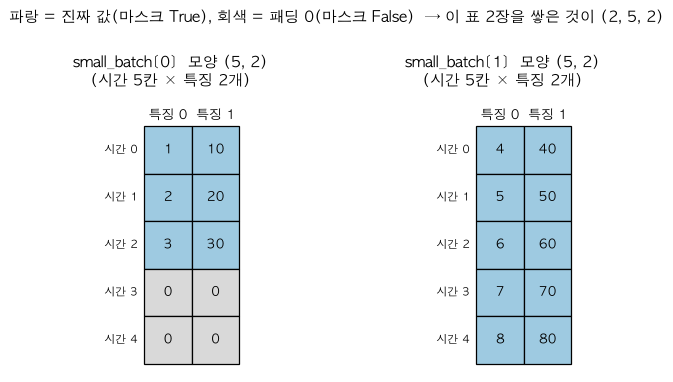

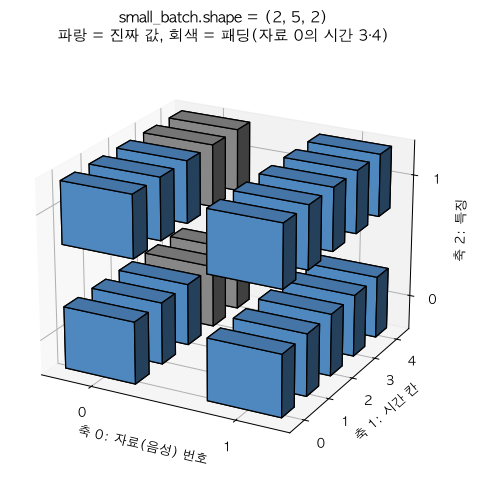

In [ ]:
# 목적: 3-1의 small_batch (2, 5, 2)를 "축별로" 읽고 그림으로 확인합니다.
# 앞의 3-1 코드 셀(small_batch, small_mask를 만든 셀)을 먼저 실행해야 합니다.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ① 숫자로 읽기: 인덱스 [자료 번호, 시간 번호, 특징 번호]로 값 하나를 꺼냅니다.
print("전체 모양 (자료 수, 시간 칸 수, 특징 수):", small_batch.shape, "| 축 개수(ndim):", small_batch.ndim)
print("원소 개수:", small_batch.size, "= 2 × 5 × 2")
print("small_batch[0]       → 첫 번째 자료 전체, 모양", small_batch[0].shape)
print("small_batch[0, 2]    → 첫 번째 자료의 3번째 시간 칸:", small_batch[0, 2], "(특징 2개)")
print("small_batch[0, 2, 1] → 그 칸의 두 번째 특징:", small_batch[0, 2, 1])
print("small_batch[0, 3]    → 첫 번째 자료의 4번째 시간 칸:", small_batch[0, 3], "(패딩 = 0)")
print("small_batch[1, 4, 1] → 두 번째 자료의 5번째 시간 칸, 두 번째 특징:", small_batch[1, 4, 1])

# ② 그림 1: 자료마다 '시간 × 특징' 표 한 장씩. 3차원 배열 = 이런 표를 자료 수만큼 쌓은 것
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for d, ax in enumerate(axes):
    ax.set_title(f"small_batch[{d}]  모양 {small_batch[d].shape}\n(시간 5칸 × 특징 2개)")
    for t in range(5):
        for f in range(2):
            real = small_mask[d, t]                      # 이 시간 칸이 진짜 자료인가
            ax.add_patch(Rectangle((f, 4 - t), 1, 1, facecolor="#9ecae1" if real else "#d9d9d9", edgecolor="black"))
            ax.text(f + 0.5, 4 - t + 0.5, f"{small_batch[d, t, f]:g}", ha="center", va="center")
    for t in range(5):
        ax.text(-0.15, 4 - t + 0.5, f"시간 {t}", ha="right", va="center", fontsize=9)
    ax.text(0.5, 5.15, "특징 0", ha="center"); ax.text(1.5, 5.15, "특징 1", ha="center")
    ax.set_xlim(-1.0, 2.1); ax.set_ylim(-0.2, 5.7); ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("파랑 = 진짜 값(마스크 True), 회색 = 패딩 0(마스크 False)  → 이 표 2장을 쌓은 것이 (2, 5, 2)", y=1.0)
plt.tight_layout(); plt.show()

# ③ 그림 2: 같은 배열을 3차원 상자로 보기 (한 칸 = 숫자 1개, 총 2×5×2 = 20칸)
# 칸 사이에 빈 공간을 두어(2배 격자) 안쪽 칸과 패딩(회색)이 가려지지 않게 펼쳐 그립니다.
n_d, n_t, n_f = small_batch.shape
filled = np.zeros((2 * n_d - 1, 2 * n_t - 1, 2 * n_f - 1), dtype=bool)
colors = np.empty(filled.shape + (4,))
for d in range(n_d):
    for t in range(n_t):
        for f in range(n_f):
            filled[2 * d, 2 * t, 2 * f] = True
            colors[2 * d, 2 * t, 2 * f] = (0.35, 0.6, 0.85, 1.0) if small_mask[d, t] else (0.6, 0.6, 0.6, 1.0)
fig = plt.figure(figsize=(7.5, 5.5))
ax = fig.add_subplot(projection="3d")
ax.voxels(filled, facecolors=colors, edgecolor="k")
ax.set_xlabel("축 0: 자료(음성) 번호")
ax.set_ylabel("축 1: 시간 칸")
ax.set_zlabel("축 2: 특징")
ax.set_xticks([0.5 + 2 * i for i in range(n_d)]); ax.set_xticklabels(range(n_d))
ax.set_yticks([0.5 + 2 * i for i in range(n_t)]); ax.set_yticklabels(range(n_t))
ax.set_zticks([0.5 + 2 * i for i in range(n_f)]); ax.set_zticklabels(range(n_f))
ax.view_init(elev=22, azim=-62)
ax.set_title("small_batch.shape = (2, 5, 2)\n파랑 = 진짜 값, 회색 = 패딩(자료 0의 시간 3·4)")
plt.tight_layout(); plt.show()

### 실습 3-2 · 제공 WAV → Log-Mel 특징 변환 [기본 실습]

4강의 STFT·Mel 내용을 짧게 복습해 입력 형태를 연결합니다. **4강 설정과 일치하도록 16kHz, 512/128, Mel 40개**를 사용합니다. 원래 출력은 `(Mel, 시간)`이고 배치에서는 `(시간, Mel)`로 바꿉니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-2).


In [ ]:
# 목적: WAV를 동일한 조건의 (시간, Mel 특징) 배열로 바꿉니다.
# 수업용 전처리이며, 실제 모델의 공식 입력 규격과는 구별해야 합니다.
def prepare_mono_16k(path):
    sr, sound = load_audio(path)
    if sound.ndim == 2:
        # WAV의 2차원 배열은 (시간, 채널)입니다. 채널 축을 평균하여 모노로 만듭니다.
        sound = sound.mean(axis=1)  # 왼쪽·오른쪽 채널 평균
    if sr != 16000:
        # 최대공약수로 변환 비율을 줄입니다. 예: 22050→16000은 up=320, down=441입니다.
        factor = gcd(sr, 16000)
        # 필터링을 포함한 리샘플링으로 샘플 수를 바꿉니다. 재생 rate만 바꾸는 것과 다릅니다.
        sound = resample_poly(sound, 16000 // factor, sr // factor)
    # 변환 후 실제 샘플 간격에 맞는 주파수와 파형을 함께 반환합니다.
    return 16000, sound


def logmel(sound, sr, n_mels=40):
    """4강과 연결되는 수업용 HTK Mel 계산: 출력은 (Mel 칸, 시간)."""
    sound = np.asarray(sound)
    if sound.ndim != 1 or len(sound) < 512:
        raise ValueError("512샘플 이상인 모노 음성이 필요합니다.")
    # 512샘플 창을 128샘플씩 이동합니다. 겹침은 512-128=384샘플입니다.
    # 16kHz에서 창은 32ms, 이동은 8ms입니다.
    # boundary=None, padded=False: 양 끝 확장이나 마지막 부족 구간의 0 채우기를 하지 않습니다.
    # z는 (주파수 칸, 시간 프레임)의 복소수 배열입니다.
    # [왼쪽 변수 3개 hz, times, z 는 무엇인가] stft()는 값을 3개 돌려주고, 순서대로 받습니다.
    #   hz    : 세로(주파수) 이름표. 길이 257 → 0, 31.25, 62.5, … , 8000 Hz (칸 간격 = sr ÷ 512 = 31.25 Hz)
    #   times : 가로(시간) 이름표. 각 분석 구간(프레임)의 '가운데 시각(초)'. 0.016, 0.024, 0.032, … (간격 128샘플 = 0.008초)
    #   z     : 표 본체(복소수). z[i, j] = "j번째 시간 구간 안에 hz[i] Hz 성분이 들어 있는 정도". 모양 (257, 프레임 수)
    #   → hz[i]와 times[j]로 z[i, j]가 '몇 Hz, 몇 초'의 값인지 알 수 있습니다.
    # [어디서 더 보나] 바로 아래 새 md 셀 "Q. hz, times, z는 무엇인가?" + 이전 수업 자료:
    #   · 03_FFT_STFT_그림으로_소리읽기.ipynb : compute_stft 함수와 인자별 주석(33번 셀), noverlap 식(34번 셀),
    #     결과 모양 (257, 122)(36번 셀), frequencies·frame_times·spectrum 주석(37번 셀), 크기(abs)와 scaling="spectrum"(38번 셀)
    #   · lesson04_student_practice.ipynb : 같은 stft 호출이 들어 있는 logmel() (4강 3-B) — 변수명은 hz, times, spectrum
    #   (셀 번호는 2026-10-27 기준이며, 셀을 추가·삭제하면 달라질 수 있습니다. 제목이나 코드 이름으로 찾으세요.)
    # [괄호 안 인자 요약] window="hann": 구간 양 끝을 부드럽게 줄임 / nperseg=512: 한 구간 샘플 수 / noverlap=384: 이웃 구간과 겹치는 샘플 수(=512-128)
    #   nfft=512: FFT 크기(구간 길이와 같게) / boundary=None·padded=False: 앞뒤에 샘플을 덧붙이지 않음 /
    #   detrend=False: 구간 평균·추세를 빼지 않음 / scaling="spectrum": 크기 기준(창의 합으로 나눔)
    hz, times, z = stft(
        sound, fs=sr, window="hann", nperseg=512, noverlap=384,
        nfft=512, boundary=None, padded=False, detrend=False, scaling="spectrum"
    )
    # 복소수의 크기를 구하고 제곱해 파워로 바꿉니다. 크기와 파워를 혼용하지 않습니다.
    power = np.abs(z) ** 2
    # HTK 방식으로 주파수 축을 Mel 축으로 바꾸어 경계를 정합니다.
    to_mel = lambda f: 2595 * np.log10(1 + f / 700)
    to_hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    # 0~나이퀴스트 주파수(sr/2)를 Mel 간격으로 나누고 다시 Hz로 돌립니다.
    # 양 끝 경계를 포함해 n_mels+2개의 점으로 삼각 필터를 배치합니다.
    edges = to_hz(np.linspace(0, to_mel(sr / 2), n_mels + 2))
    # 각 행은 Mel 필터 하나, 각 열은 STFT 주파수 칸에 부여할 가중치입니다.
    filters = np.zeros((n_mels, len(hz)))
    for k in range(n_mels):
        left, center, right = edges[k:k + 3]
        rising = (hz - left) / (center - left)
        falling = (right - hz) / (right - center)
        # 중앙에서 1, 좌우 경계에서 0인 삼각형 가중치를 만듭니다.
        filters[k] = np.maximum(0, np.minimum(rising, falling))
    # (Mel 칸, 주파수 칸) × (주파수 칸, 시간) → (Mel 칸, 시간).
    # 각 시간 프레임의 주파수별 파워를 필터 가중치로 묶습니다.
    mel_power = filters @ power
    # 0의 로그를 피하려고 파워의 최솟값을 1e-10으로 제한합니다.
    # 파워이므로 10×log10을 사용하며 바닥값은 -100입니다. 기준 1의 로그 파워 표현입니다.
    log_mel = 10 * np.log10(np.maximum(mel_power, 1e-10))
    return {"log_mel": log_mel, "times": times}


# 선택한 ID와 특징의 순서를 함께 유지합니다.
BATCH_INDICES = [0, 1, 2]
batch_rows = [items[index] for index in BATCH_INDICES]
sequences = []
for row in batch_rows:
    sr, mono = prepare_mono_16k(DATA / row["file"])
    mel = logmel(mono, sr, n_mels=40)["log_mel"]
    # (Mel 40칸, 시간)을 (시간, Mel 40칸)으로 바꾸어 뒤의 배치 축 순서와 맞춥니다.
    # 전치 자체는 특징값을 바꾸지 않으며, float32는 저장·연산용 실수형입니다.
    features = mel.T.astype(np.float32)
    sequences.append(features)
    print(row["id"], "/ Mel 원래 모양:", mel.shape, "/ 전치 후:", features.shape)

1272-128104-0001 / Mel 원래 모양: (40, 609) / 전치 후: (609, 40)
1272-128104-0006 / Mel 원래 모양: (40, 792) / 전치 후: (792, 40)
1272-128104-0008 / Mel 원래 모양: (40, 1290) / 전치 후: (1290, 40)


### Q. `hz, times, z = stft(...)`에서 `hz`, `times`, `z`는 각각 무엇인가?

수치는 이 노트북의 첫 번째 제공 WAV(`1272-128104-0001`, 16kHz, 78,336샘플 = 4.896초)에 3-2와 같은 `stft(...)` 호출을 실행해 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 한 줄 요약
- `stft()`는 값을 **3개** 돌려주고, 왼쪽의 `hz, times, z`가 그것을 **순서대로** 받습니다(튜플 풀기). 이 셋은 **"세로 이름표(hz) + 가로 이름표(times) + 표 본체(z)"** 입니다.
- 변수 이름은 사람이 붙인 것입니다. 03 노트북에서는 `frequencies, frame_times, spectrum`, 4강에서는 `hz, times, spectrum`, 여기서는 `hz, times, z`로 **같은 세 개**입니다. 중요한 것은 이름이 아니라 **돌려주는 순서(주파수 → 시간 → 표)** 입니다.

#### 2. 하나씩
| 변수 | 무엇인가 | 모양 | 값 (직접 확인) |
|---|---|---|---|
| **`hz`** | 표의 **세로(행) 이름표**: 각 행이 몇 Hz인지 | `(257,)` | `0, 31.25, 62.5, 93.75, …, 7968.75, 8000` (간격 31.25 Hz) |
| **`times`** | 표의 **가로(열) 이름표**: 각 열이 몇 초인지 (분석 구간의 **가운데 시각**) | `(609,)` | `0.016, 0.024, 0.032, …, 4.872, 4.88` (간격 0.008초) |
| **`z`** | **표 본체**: 칸마다 복소수 1개 | `(257, 609)` | 예) `z[3, 10]` = `0.00428+0.00808j` |

**`hz` (257개, 0~8000Hz)**
- 구간 하나(512샘플)를 FFT하면 칸이 `512 ÷ 2 + 1 = 257`개 나옵니다(앞 03 노트북의 `rfft` 설명과 같음). `hz`는 그 칸들이 각각 몇 Hz인지 알려 줍니다.
- 간격 = `sr ÷ nfft = 16000 ÷ 512 = 31.25 Hz`, 마지막 칸은 `sr ÷ 2 = 8000 Hz`(나이퀴스트). 03 노트북에서 본 `np.fft.rfftfreq`와 같은 계산입니다.

**`times` (609개)**
- 구간(프레임)이 **609개**라는 뜻이고, 값은 각 구간의 **가운데 시각**입니다. 첫 구간은 샘플 0~511이므로 가운데가 `256 ÷ 16000 = 0.016초`입니다(구간의 **시작**이 아니라 **중심**이라 0이 아닙니다).
- 간격 `0.008초` = 이동 간격 `128 ÷ 16000`. 마지막 구간 중심은 `4.88초`로, 전체 길이 4.896초보다 약간 작습니다(마지막 부족 구간은 채우지 않았기 때문, `padded=False`).
- 개수 공식: `(샘플 수 − 512) ÷ 128 + 1 = (78336 − 512) // 128 + 1 = 609` (03 노트북 34·36번 셀과 같은 공식).

**`z` (257 × 609 복소수 표)**
- `z[i, j]`는 **"j번째 시간 구간에서, `hz[i]` Hz 성분이 어느 정도(크기·위상) 들어 있나"** 입니다. 행 번호 `i` ↔ `hz[i]`, 열 번호 `j` ↔ `times[j]`로 짝이 맞습니다.
  - 예) `z[4, 60]` → `hz[4] = 125 Hz`, `times[60] = 0.496초` 구간의 125Hz 성분. 이 파일에서 그 시간(열 60)에 가장 큰 칸이 125Hz 칸(행 4)이었습니다.
- **복소수**인 이유: 03 노트북 12번 셀처럼 FFT는 사인·코사인 두 결과를 묶은 복소수 하나를 칸마다 돌려주기 때문입니다. 크기는 `np.abs(z)`로 꺼내고, 이 코드는 바로 다음 줄에서 `np.abs(z) ** 2`로 **파워**를 만듭니다(예: `z[3, 10]`의 크기 `0.00914`, 파워 `8.3e-05`).
- 입력이 `float32`라 `z`의 자료형은 `complex64`였습니다.

#### 3. 그림으로 보면
```text
                     times (가로: 시간, 구간의 가운데 시각)
                  0.016  0.024  0.032  …  4.88      ← times[0] … times[608]
 hz (세로)  0 Hz  [ z[0,0]   z[0,1]  …        ]
          31.25   [ z[1,0]   z[1,1]  …        ]
           62.5   [ z[2,0]   …                ]
            ⋮                                       ← z : (257행 × 609열) 복소수 표
          8000 Hz [ z[256,0] …       z[256,608]]
```
- 이 표를 `np.abs(z) ** 2`로 파워로 바꾼 것이 4강의 "STFT 파워 `(257, 247)`"(2초 음성)이고, 3-2에서는 여기에 Mel 필터(`filters @ power`)를 곱해 `(40, 609)`로 줄입니다.
- `times`는 3-2의 `logmel()` 결과 딕셔너리에도 담겨 `{"log_mel": …, "times": times}`로 돌려줍니다(시간 이름표를 보관).

#### 4. 괄호 안 인자는 어디서 설명했나 (이전 수업 자료)
| 알고 싶은 것 | 참고할 곳 |
|---|---|
| 인자 하나하나(`window`, `nperseg`, `noverlap`, `nfft`, `boundary`, `padded`, `detrend`, `scaling`) | `03_FFT_STFT_그림으로_소리읽기.ipynb` 33번 셀(`compute_stft`의 줄별 주석) |
| `noverlap = frame − hop`가 왜 이 식인가 (`512 − 128 = 384`) | 같은 노트북 34번 셀 |
| 결과 모양 `(257, …)`, 프레임 개수 공식 | 같은 노트북 36번 셀 |
| `frequencies, frame_times, spectrum`의 설명과 스펙트로그램 | 같은 노트북 37번 셀 |
| `abs`로 크기를 꺼내는 것, `scaling="spectrum"`의 크기 의미 | 같은 노트북 38번 셀 |
| 같은 호출이 들어 있는 `logmel()` 전체 흐름 | `lesson04_student_practice.ipynb` 4강 실습 3-B |
- 셀 번호는 2026-10-27 기준입니다. 셀을 추가·삭제하면 달라질 수 있으니 제목이나 코드 이름으로 찾으세요.

### 실습 3-3 · 실제 음성 특징 배치·마스크 시각화 [기본 실습]

긴 음성과 짧은 음성을 한 배열로 묶습니다. `lengths`는 실제 음성 프레임의 수이고, `mask=False`는 뒤에 추가한 패딩입니다. **원본 무음은 패딩이 아닙니다.**
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-3).


원래 길이: [ 609  792 1290]
배치 (파일, 시간, 특징): (3, 1290, 40)
마스크 (파일, 시간): (3, 1290)
각 파일의 패딩 프레임 수: [681 498   0]
마스크의 실제 길이와 lengths가 같은가: True


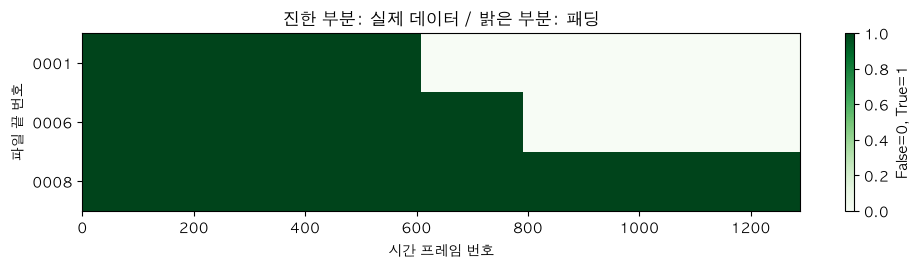

In [14]:
# 목적: 특징 배열들을 (자료 수, 최대 시간, 특징 수)로 묶고 실제 구간을 표시합니다.
def make_batch(feature_list):
    # 입력 배열이 비거나 특징 수가 서로 다르면 의미 없는 배치가 만들어지므로 검사합니다.
    # 전치한 특징 배열의 len은 원래 음성 샘플 수가 아니라 STFT 프레임 수입니다.
    if not feature_list or any(x.ndim != 2 or len(x) == 0 for x in feature_list):
        raise ValueError("비어 있지 않은 (시간, 특징) 배열이 필요합니다.")
    if len({x.shape[1] for x in feature_list}) != 1:
        raise ValueError("모든 음성의 특징 수가 같아야 합니다.")
    lengths = np.array([len(features) for features in feature_list], dtype=np.int64)
    max_length = int(lengths.max())
    # 같은 Mel 설정으로 만들었으므로 특징 수는 모두 같습니다. 이번에는 40개입니다.
    feature_count = feature_list[0].shape[1]
    # 가장 긴 자료에 맞춰, 특징을 넣을 공간을 만들고, 짧은 자료 뒤의 빈 공간은 0으로 남깁니다.
    batch = np.zeros((len(feature_list), max_length, feature_count), dtype=np.float32)
    mask = np.zeros((len(feature_list), max_length), dtype=bool) # 0 = false
    for index, features in enumerate(feature_list):
        length = len(features)
        batch[index, :length] = features
        # 실제 무음도 원래 데이터이므로 True입니다. 추가한 패딩만 False로 둡니다.
        mask[index, :length] = True
    return batch, mask, lengths

batch, mask, lengths = make_batch(sequences)
print("원래 길이:", lengths)
print("배치 (파일, 시간, 특징):", batch.shape)
print("마스크 (파일, 시간):", mask.shape)
# ~mask는 실제/패딩 표시를 뒤집습니다. 이를 더하면 각 자료의 패딩 칸 수가 됩니다.
print("각 파일의 패딩 프레임 수:", (~mask).sum(axis=1))
print("마스크의 실제 길이와 lengths가 같은가:", np.array_equal(mask.sum(axis=1), lengths))

plt.figure(figsize=(10, 2.8))
# 행은 음성 파일, 열은 시간 프레임입니다. False/True를 0/1 색으로 보여 줍니다.
plt.imshow(mask, aspect="auto", interpolation="nearest", vmin=0, vmax=1, cmap="Greens")
plt.yticks(range(len(batch_rows)), [row["id"][-4:] for row in batch_rows])
plt.xlabel("시간 프레임 번호")
plt.ylabel("파일 끝 번호")
plt.title("진한 부분: 실제 데이터 / 밝은 부분: 패딩")
plt.colorbar(label="False=0, True=1")
plt.tight_layout()
plt.show()


### 실습 3-4 · 선택한 파일 조합에 따른 패딩 비교 [직접 변경]

`PRACTICE_INDICES = [0, 4]`를 `[0, 2, 4]`로 바꾼 뒤 `배치 모양`, `길이`, `패딩 수`의 차이를 확인합니다. 별도 변수에 결과를 저장하므로 3-3의 본 배치는 유지됩니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-4).


In [17]:
# 목적: 길이가 다른 자료의 패딩·마스크를 확인합니다.
# 선택한 파일 조합만 바꾸어 패딩 양을 비교합니다.
# practice_ 변수에 따로 저장하므로 본 시연의 batch와 정답 순서는 바뀌지 않습니다.
PRACTICE_INDICES = [0, 4]  # 학생이 바꿀 값: [0, 2, 4]
practice_features = []
for index in PRACTICE_INDICES:
    sr, mono = prepare_mono_16k(DATA / items[index]["file"])
    practice_features.append(logmel(mono, sr)["log_mel"].T.astype(np.float32))
# 선택한 파일 수와 가장 긴 파일에 따라 첫째·둘째 축이 달라집니다. Mel 수는 40으로 유지됩니다.
practice_batch, practice_mask, practice_lengths = make_batch(practice_features)
print("선택한 파일:", [items[index]["id"] for index in PRACTICE_INDICES])
print("실제 길이:", practice_lengths)
print("배치 모양:", practice_batch.shape)
print("패딩 프레임 수:", (~practice_mask).sum(axis=1))


선택한 파일: ['1272-128104-0001', '1272-128104-0014']
실제 길이: [609 354]
배치 모양: (2, 609, 40)
패딩 프레임 수: [  0 255]


### 실습 3-5 · 마스크 적용 평균이 필요한 이유 [기본 실습]

이 숫자는 **가상 오차**입니다. 패딩 위치를 실제 데이터처럼 평균에 포함하면 어떤 차이가 생기는지 확인합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-5).


In [18]:
# 목적: 가상 오차에 대한 패딩 포함 평균과 실제 구간 평균을 비교합니다.
# 실제 모델의 손실이 아닌 가상 오차입니다. 앞 두 칸만 실제 값이고 뒤는 패딩입니다.
# 패딩의 오차가 늘 0이라는 뜻이 아니라 평균의 계산 대상 차이를 설명하는 예입니다.
toy_errors = np.array([1.0, 3.0, 0.0, 0.0])
toy_mask = np.array([True, True, False, False])
print("전체를 잘못 평균:", toy_errors.mean())
# True인 실제 오차만 골라 평균내므로 분모는 4가 아니라 2입니다.
print("실제 구간만 평균:", toy_errors[toy_mask].mean())


전체를 잘못 평균: 1.0
실제 구간만 평균: 2.0


### 실습 3-6 · 패딩을 2·4·6칸으로 바꿀 때 평균 [직접 변경]

기본 숫자 실습으로 마스크가 필요한 이유를 확인한 다음 `PADDING_COUNT` 값을 바꾸어 같은 평균이 어떻게 달라지는지 관찰합니다. 이론의 실습 3-6과 연결됩니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-6).


In [19]:
# 목적: 가상 오차에 대한 패딩 포함 평균과 실제 구간 평균을 비교합니다.
# 실제 오차 [1, 3]은 고정하고 패딩 수만 바꿉니다. 전체 평균이 낮아져도 모델 향상이 아닙니다.
PADDING_COUNT = 2  # 학생이 바꿀 값: 2 → 4 → 6
actual_errors = np.array([1.0, 3.0])
errors = np.concatenate([actual_errors, np.zeros(PADDING_COUNT)])
# 원래 오차의 길이인 2를 기준으로 첫 두 칸만 True로 만듭니다.
# 오차값이 0인지 비교해 마스크를 만들면 실제 오차 0도 잘못 제외할 수 있습니다.
error_mask = np.arange(len(errors)) < len(actual_errors)
print("오차 배열:", errors)
print("실제 구간 마스크:", error_mask)
print("전체 칸 수:", len(errors))
print("패딩 포함 평균:", errors.mean())
print("실제 구간 평균:", errors[error_mask].mean())


오차 배열: [1. 3. 0. 0.]
실제 구간 마스크: [ True  True False False]
전체 칸 수: 4
패딩 포함 평균: 1.0
실제 구간 평균: 2.0


**3교시 관찰 기록 — 직접 작성**

- `(자료 수, 시간 프레임, Mel 수)`에서 각 축은 무엇인가요? →
- 왜 마스크는 `(자료 수, 시간 프레임)` 형태인가요? →
- 실제 녹음의 조용한 구간과 추가 패딩을 어떻게 구별하나요? →

### 자율실습 3-S · 내 음성 품질 관찰과 X 배치 [직접 작성]

1-S에서 만든 음성 3개에 동일한 전처리를 적용합니다. 제공 데이터의 코드를 **직접 재사용**하여 본인의 X 배치를 만드세요. 원본 WAV가 44.1kHz, 48kHz, 스테레오여도 전처리 함수가 16kHz 모노로 변환합니다. 단 PCM WAV가 아닌 M4A는 먼저 WAV로 내보내야 합니다.

`peak`는 최대 절댓값이고 `rms`는 평균적인 음량을 대략 비교하기 위한 지표입니다. 수치가 좋다고 전사가 자동으로 정확해지는 것은 아닙니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-S).


In [20]:
# 목적: 내 녹음의 길이/음량을 관찰한 뒤 3교시와 같은 X 배치를 만듭니다.
def personal_audio_quality(sound):
    sound = np.asarray(sound, dtype=np.float32)
    return float(np.max(np.abs(sound))), float(np.sqrt(np.mean(sound**2)))

my_X = my_X_mask = my_X_lengths = my_X_ids = None
if MY_MANIFEST.is_file():
    my_rows = read_json(MY_MANIFEST)
    check_manifest(my_rows, DATA, expected_count=3)
    my_features = []
    my_X_ids = [r["id"] for r in my_rows]
    for row in my_rows:
        sr, mono = prepare_mono_16k(DATA / row["file"])
        peak, rms = personal_audio_quality(mono)
        mel = logmel(mono, sr, n_mels=40)["log_mel"]
        my_features.append(mel.T.astype(np.float32))
        print(row["id"], "길이", round(len(mono)/sr, 2), "초", "Peak", round(peak, 3),
              "RMS", round(rms, 3), "프레임", mel.shape[1])
    my_X, my_X_mask, my_X_lengths = make_batch(my_features)
    print("내 X:", my_X.shape, "마스크:", my_X_mask.shape)
    print("내 파일별 패딩 수:", (~my_X_mask).sum(axis=1).tolist())
    assert np.array_equal(my_X_mask.sum(axis=1), my_X_lengths)
else:
    print("1-S에서 내 WAV 3개를 준비하면 내 X 배치를 만들 수 있습니다.")

1-S에서 내 WAV 3개를 준비하면 내 X 배치를 만들 수 있습니다.


### 자율실습 3-T · 녹음 품질이 좋지 않은 사례 비교 [선택]

한 파일을 재생해 보고 (1) 매우 작은 음량 (2) 앞뒤 긴 무음 (3) 파형 끝이 잘린 경우를 **실제 파일을 삭제하지 않고** 관찰하세요. `Peak`가 1 근처라고 해서 클리핑이 반드시 발생한 것은 아닙니다. 반복적으로 샘플이 최대·최소값에 붙는지 파형·청취로 확인해야 합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-3-T).


In [21]:
# 목적: 내 원본 파일을 건드리지 않고 음량 변화가 Peak/RMS에 주는 영향을 확인합니다.
if MY_MANIFEST.is_file():
    sr, sample = prepare_mono_16k(DATA / my_rows[0]["file"])
    for label, trial in [("원본", sample), ("작은 음량", sample*0.1),
                         ("증폭 후 제한", np.clip(sample*8, -1, 1))]:
        p, r = personal_audio_quality(trial)
        clip_ratio = float(np.mean(np.abs(trial)>=0.99))
        print(label, "Peak", round(p,3), "RMS", round(r,3), "최대값 근접 비율", f"{clip_ratio:.2%}")
else:
    print("이 실습은 내 녹음이 준비된 다음 진행합니다.")

이 실습은 내 녹음이 준비된 다음 진행합니다.


---

# 2026.10.27(화) 22h5~

## 4교시 · 정답 토큰 ID y를 만들고 음성과 연결하기

**핵심 질문:** 소리 X와 정답 문장 y를 **동일한 ID 순서**로 하나의 배치에 담을 수 있을까요?

**이번 교시의 결과:** 제공 자료로 토큰·`<unk>`·`<pad>`·정답 마스크를 관찰하고 최종 연결을 검증합니다. 이어서 자기 목소리로 만든 데이터에도 같은 과정을 적용합니다.

### 실습 4-1 · 어절 사전, 미등록 토큰 `<unk>` [기본 실습]

정답 문장은 곧바로 모델이 다룰 숫자 배열이 아닙니다. 이 교재의 어절 토큰화는 **원리 설명용**이며, 실제 Whisper 등의 공식 토크나이저와 동일하지 않습니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-1).


In [15]:
# 목적: 어절을 토큰 ID로 바꾸고 사전의 역할을 비교합니다.
# 수업용 어절 사전입니다. 번호는 의미의 크기가 아니라 토큰을 찾기 위한 ID입니다.
# 0은 패딩, 1은 미등록 토큰에 예약합니다. 실제 Whisper 토크나이저는 아닙니다.
vocab = {"<pad>": 0, "<unk>": 1, "음성": 2, "모델": 3, "공부": 4}
sentence = "음성 모델 실습"
# 공백 기준 어절로 나눕니다. 한국어 형태소를 분석하거나 문장부호를 제거하지는 않습니다.
tokens = sentence.split()
ids = []
for token in tokens:
    # 등록된 토큰이면 그 번호, 없으면 <unk>의 번호를 사용합니다.
    token_id = vocab.get(token, vocab["<unk>"])
    ids.append(token_id)
    print(token, "→", token_id)
print("전체 ID:", ids)


음성 → 2
모델 → 3
실습 → 1
전체 ID: [2, 3, 1]


### Q. `vocab.get(token, vocab["<unk>"])`는 무슨 뜻인가? (문법 풀이)

아래 값은 직접 실행해 확인했습니다. 4-1·4-2·4-3에서 같은 모양의 줄이 반복해서 나옵니다.

#### 1. 한 줄 뜻
> **"`vocab`(사전)에서 `token`의 번호를 찾아라. 만약 사전에 없으면 `<unk>`의 번호(1)를 대신 써라."**

#### 2. 세 조각으로 나눠 읽기
```python
vocab.get( token ,  vocab["<unk>"] )
│     │      │            └─ ③ 두 번째 인자 = 기본값: 못 찾았을 때 대신 돌려줄 값
│     │      └─ ② 첫 번째 인자 = 찾을 키(열쇠): 지금 보는 어절. 예) "음성", "실습"
│     └─ .get(...) : 사전(dict)의 메서드. "키로 값을 찾되, 없어도 오류를 내지 마라"
└─ vocab : {"<pad>": 0, "<unk>": 1, "음성": 2, "모델": 3, "공부": 4}  (어절 → 번호 표)
```
- **③번 `vocab["<unk>"]` 자체가 별도의 값 찾기**입니다. 사전에서 `"<unk>"`라는 키의 값을 꺼내면 `1`이므로, 전체는 사실상 **`vocab.get(token, 1)`** 과 같습니다(직접 확인: 둘의 결과가 같음).
- 번호 `1`을 직접 쓰지 않고 `vocab["<unk>"]`로 쓰는 이유(제 해석, 추정): 번호가 바뀌어도 이름(`<unk>`)으로 찾으면 코드가 그대로 맞기 때문입니다.

#### 3. 두 경우의 계산 과정
| 어절 `token` | 사전에 있나 | `vocab.get(token, 1)`의 결과 |
|---|---|---|
| `"음성"` | 있음 | **2** (사전의 값) — 기본값은 쓰이지 않음 |
| `"실습"` | **없음** | **1** (기본값 `<unk>`) |

#### 4. `vocab[token]`과의 차이
| 코드 | 키가 있을 때 | 키가 없을 때 |
|---|---|---|
| `vocab["실습"]` | 값 | **`KeyError`로 프로그램이 멈춤** |
| `vocab.get("실습")` | 값 | `None` (기본값을 생략하면 `None`) |
| `vocab.get("실습", 1)` | 값 | **1** (정한 기본값) |
- 그래서 "모르는 단어가 와도 멈추지 않고 `<unk>`로 처리"하고 싶을 때 `.get(키, 기본값)`을 씁니다.

#### 5. `if`로 풀어 쓴 같은 뜻
```python
if token in vocab:           # 사전에 키가 있으면
    token_id = vocab[token]  # 그 번호
else:
    token_id = vocab["<unk>"]   # 없으면 <unk>의 번호
```
- 직접 확인: `"실습"`에 대해 위 `if` 문과 `vocab.get(token, vocab["<unk>"])`의 결과가 모두 `1`로 같았습니다.

#### 6. 알아 둘 점
- 두 번째 인자(기본값)는 **찾기 전에 미리 계산**됩니다. `vocab["<unk>"]`가 먼저 실행되므로, 사전에 `"<unk>"` 키가 아예 없으면 단어가 사전에 **있어도** `KeyError`가 납니다(직접 확인). 그래서 사전을 만들 때 `<unk>`를 꼭 먼저 넣어 둡니다.
- 4-2의 `[vocab.get(token, vocab["<unk>"]) for token in practice_tokens]`는 이 줄을 **어절마다 반복해 리스트로 모은 것**이고, 4-1은 같은 일을 `for` 문 + `append`로 쓴 것입니다.

### 실습 4-2 · 문장별 토큰 ID 바꾸어 보기 [직접 변경]

이론의 **실습 4-2**와 연결됩니다. 원래 사전을 고정하고 문장을 바꾸면 어떤 어절이 `<unk>`로 변하는지 살펴봅니다. 실제 Whisper 토크나이저를 만드는 실습이 아닙니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-2).


In [16]:
# 목적: 어절을 토큰 ID로 바꾸고 사전의 역할을 비교합니다.
# 같은 사전으로 다른 문장을 변환합니다. 사전에 없는 어절만 <unk>의 ID로 바뀝니다.
# 예: 공부와 공부.는 다른 문자열이므로 문장부호도 변환 결과에 영향을 줍니다.
PRACTICE_SENTENCE = "음성 공부 실습"  # 학생이 바꿀 값
practice_tokens = PRACTICE_SENTENCE.split()
practice_ids = [vocab.get(token, vocab["<unk>"]) for token in practice_tokens]
# 원문에서 어떤 어절이 미등록인지 별도로 보관해야 원인을 설명할 수 있습니다.
unknown_tokens = [token for token in practice_tokens if token not in vocab]
print("토큰:", practice_tokens)
print("ID:", practice_ids)
print("미등록 어절:", unknown_tokens)


토큰: ['음성', '공부', '실습']
ID: [2, 4, 1]
미등록 어절: ['실습']


### Q. 실습 4-2 설명 — 같은 사전으로 문장만 바꾸면 무슨 일이 생기나?

아래 수치는 4-1·4-2 코드를 이 환경에서 실행해 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 이 실습의 목적
- 4-1에서 만든 `vocab`(사전)을 **그대로 두고** 입력 문장만 바꿔서, **"사전에 있는 어절은 번호가 같고, 없는 어절만 `<unk>`(1)로 바뀐다"** 는 것을 확인합니다.
- 사전은 "문장마다 새로 만드는 것"이 아니라 **한 번 정해 두고 계속 쓰는 번호표**라는 점이 핵심입니다. 같은 어절은 어떤 문장에서든 같은 ID를 받습니다.

#### 2. 코드 읽기
| 줄 | 하는 일 | 결과 (`PRACTICE_SENTENCE = "음성 공부 실습"`) |
|---|---|---|
| `PRACTICE_SENTENCE.split()` | 공백 기준으로 어절 분리 | `['음성', '공부', '실습']` |
| `vocab.get(token, vocab["<unk>"])` | 사전에서 ID를 찾고, **없으면 기본값 1(`<unk>`)** | `2, 4, 1` |
| `[... for token in practice_tokens]` | 위 계산을 어절마다 반복해 리스트로 (4-1의 `for`+`append`를 한 줄로 쓴 것, 결과 동일) | `[2, 4, 1]` |
| `[token for token in ... if token not in vocab]` | **사전에 없는 어절만 따로 모음** | `['실습']` |

- `vocab.get(키, 기본값)`과 `vocab[키]`의 차이: `vocab["실습"]`은 키가 없으면 `KeyError`로 멈추고, `vocab.get("실습", 99)`는 오류 없이 기본값(99)을 돌려줍니다(직접 확인). 이 코드는 기본값을 `vocab["<unk>"]`(= 1)로 줍니다.
- **`unknown_tokens`를 따로 보관하는 이유**(코드 주석): ID만 `[2, 4, 1]`로 남으면 "1이 어느 단어였는지"를 알 수 없습니다. 원문에서 미등록 어절을 별도로 적어 둬야 원인을 설명할 수 있습니다.

#### 3. 출력 읽기 (직접 확인)
```text
토큰: ['음성', '공부', '실습']
ID:   [2, 4, 1]              ← 음성=2, 공부=4는 사전 번호, 실습은 사전에 없어 1(<unk>)
미등록 어절: ['실습']
```

#### 4. 직접 바꿔 볼 때 알아 둘 점 (직접 확인)
- 코드 주석의 예: `"음성 공부. 실습"`처럼 **마침표가 붙은 `공부.`는 사전의 `공부`와 다른 문자열**이라 `[2, 1, 1]`이 됩니다(`split()`은 공백으로만 자르고 문장부호를 떼지 않음).
- 공백이 여러 개 있어도(`"음성  공부"`) `split()`은 알아서 정리해 `['음성', '공부']`가 됩니다.
- 서로 **다른 미등록 어절은 모두 같은 `1`**이 됩니다(`"실습 연습"` → `[1, 1]`). `<unk>`는 "모르는 단어"라는 표시만 하고 어떤 단어인지는 담지 못합니다.

### 실습 4-3 · 미등록 어절을 남기는 이유 [기본 실습]

새 어절을 사전에 추가하는 경우, `<unk>`를 쓰는 경우, 아예 삭제하는 경우를 비교합니다. 토큰을 삭제하면 원래 문장의 길이·위치를 잃습니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-3).


In [17]:
# 목적: 미등록 토큰을 남기기 / 사전 확장 / 미등록 토큰 삭제를 비교합니다.
# 수업용 사전 복사본만 바꿉니다. 실제 학습된 모델의 사전을 임의로 바꾸는 작업과는 다릅니다.
vocab_v2 = vocab.copy()
vocab_v2["실습"] = 5
comparison_tokens = "음성 공부 실습".split()
old_ids = [vocab.get(token, vocab["<unk>"]) for token in comparison_tokens]
new_ids = [vocab_v2.get(token, vocab_v2["<unk>"]) for token in comparison_tokens]
# 비교용으로 미등록 어절을 삭제합니다. 이렇게 하면 그 어절이 있던 위치와 길이도 잃습니다.
deleted_ids = [vocab[token] for token in comparison_tokens if token in vocab]
print("기존 사전:", old_ids)
print("사전 v2:", new_ids)
print("미등록 어절을 삭제한 경우:", deleted_ids)

# 역방향 사전으로 ID를 다시 읽습니다.
# ID → 토큰으로 거꾸로 찾는 표입니다. <unk>에서 원래 미등록 단어를 복원할 수는 없습니다.
id_to_token = {number: token for token, number in vocab.items()}
print("기존 사전으로 되읽기:", [id_to_token[number] for number in old_ids])
print("원래 vocab은 그대로:", vocab)


기존 사전: [2, 4, 1]
사전 v2: [2, 4, 5]
미등록 어절을 삭제한 경우: [2, 4]
기존 사전으로 되읽기: ['음성', '공부', '<unk>']
원래 vocab은 그대로: {'<pad>': 0, '<unk>': 1, '음성': 2, '모델': 3, '공부': 4}


### Q. 실습 4-3 설명 — 미등록 어절을 처리하는 세 가지 방법과 `<unk>`를 남기는 이유

수치는 4-3 코드를 실행해 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 이 실습의 목적
- 사전에 없는 어절(`실습`)을 어떻게 다룰지 **세 방법을 같은 문장 `"음성 공부 실습"`으로 비교**합니다. 결론은 "삭제하면 안 되고, `<unk>`로 남기거나(원문 구조 보존) 사전을 늘리는 것"입니다.

#### 2. 세 방법 비교 (출력 그대로)
| 방법 | 코드 | ID 결과 | 길이 | 특징 |
|---|---|---|---|---|
| ① `<unk>`로 남기기 | `vocab.get(token, vocab["<unk>"])` | `[2, 4, 1]` | 3 | 위치·길이 보존, 단 **어떤 단어였는지는 잃음** |
| ② 사전 늘리기 | `vocab_v2["실습"] = 5` 후 변환 | `[2, 4, 5]` | 3 | 단어 정보까지 보존. 새 사전 번호가 필요 |
| ③ 삭제하기 | `if token in vocab`인 것만 | `[2, 4]` | **2** | 길이가 줄고 **원래 어느 위치에 있었는지도 잃음** |

- ③은 중간 어절이 사라지면 뒤 단어들이 앞으로 당겨져 문장 구조가 달라집니다. 직접 확인: `"음성 공부 실습 모델"`을 ③으로 처리하면 `[2, 4, 3]`이 되어 "실습"이 있던 자리가 어딘지 알 수 없지만, ①은 `[2, 4, 1, 3]`로 **자리가 남아** 있습니다.
- 음성 인식에서 이 위치·길이가 중요한 이유 **(일반 지식)**: 소리(X)와 정답(y)을 짝지어 비교할 때 정답의 길이와 순서가 흐트러지면 올바르게 평가하기 어렵습니다. 그래서 모르는 단어도 **자리는 남기고** 표시만 합니다.

#### 3. 코드 읽기
- `vocab_v2 = vocab.copy()` : 사전을 **복사**해서 복사본에만 `"실습": 5`를 넣습니다. 그래서 출력 마지막 줄처럼 **원래 `vocab`은 그대로**(`길이 5`, v2는 `6`)입니다. 복사하지 않고 `vocab["실습"] = 5`를 하면 원본이 바뀝니다. (2-1의 `row.copy()`와 같은 이유)
- 학습이 끝난 실제 모델의 사전은 이렇게 임의로 늘릴 수 없다는 것이 코드 주석의 경고입니다. ID가 곧 모델 내부 번호표(예: 임베딩 표의 행)에 대응하기 때문입니다 **(일반 지식)**. 이 실습은 "수업용 사전 복사본"만 바꿉니다.
- `deleted_ids = [vocab[token] for token in ... if token in vocab]` : `if token in vocab`으로 **미등록 어절을 걸러서 버린** 것이고, 그래서 `vocab[token]`(없으면 오류)을 안전하게 쓸 수 있습니다.
- **역방향 사전**: `id_to_token = {number: token for token, number in vocab.items()}` → `{0: '<pad>', 1: '<unk>', 2: '음성', 3: '모델', 4: '공부'}`. **ID로 단어를 거꾸로 찾는 표**입니다(번호 → 단어). `old_ids = [2, 4, 1]`을 되읽으면 `['음성', '공부', '<unk>']`로, `<unk>`의 자리에서 원래 단어 `실습`은 **복원할 수 없습니다**(출력에서 확인). 그래서 4-2의 `unknown_tokens`처럼 원문을 따로 보관해야 합니다.

### 4-1 ~ 4-4 흐름과 연결 — 문장이 어떻게 모델용 정답 배열 y가 되는가

아래 내용은 이 노트북의 4-1~4-7 코드와 출력을 따라가며 정리했습니다(수치는 저장된 출력과 직접 실행 결과). 4-4 이후는 이 셀 뒤 실습의 요약입니다.

#### 1. 한눈에 보는 흐름
```text
정답 문장 (글자)
  │ 4-1  사전(vocab) 만들고, 어절 → ID  (모르는 어절은 <unk>=1, 빈칸 채움용 <pad>=0 예약)
  │ 4-2  같은 사전으로 '다른 문장'을 바꿔 보기 → 사전에 없는 어절만 <unk>, 미등록 어절은 따로 기록
  │ 4-3  <unk>를 남길지·사전을 늘릴지·삭제할지 비교 → '삭제'는 위치·길이를 잃어 안 됨
  ▼
ID 리스트들 (문장마다 길이가 다름: [2,3,4], [2,1])
  │ 4-4  가장 긴 길이에 맞춰 <pad>(0)로 채우고 마스크 만들기 → 정답 배치 y (문장 수, 최대 토큰 수)
  ▼
4-5  실제 음성 3개의 정답 문장으로 같은 일을 수행 + 3교시의 음성 X와 같은 행 순서로 연결
4-6  ID·정답·길이·마스크 검증 (assert) → 4-7 사전까지 함께 저장
```

#### 2. 각 단계가 다음 단계에 주는 것
| 단계 | 만들어 내는 것 | 다음에서 쓰는 곳 |
|---|---|---|
| 4-1 | `vocab`(사전), 어절→ID 변환법, **예약 번호: `<pad>`=0, `<unk>`=1** | 4-2·4-3에서 같은 `vocab`을 그대로 사용 |
| 4-2 | "사전은 고정, 문장만 바뀐다", `unknown_tokens`(미등록 기록) | 4-3에서 미등록 처리 방법을 비교하는 이유 |
| 4-3 | **`<unk>`로 남기는 것**이 위치·길이를 지킨다는 결론 | 4-4에서 `<unk>`를 **실제 토큰으로 취급**(마스크 True) |
| 4-4 | `pad_token_sequences()`, 정답 배치·마스크 | 4-5에서 실제 문장에 그대로 호출 |
| 4-5 | 실제 3문장의 정답 y `(3, 17)`와 마스크, 음성 배치 `(3, 1290, 40)`와 **같은 행 순서** | 4-6 검증, 4-7 저장 |

#### 3. 3교시와 어떻게 이어지나
- 3교시에서 **소리 X**를 `(자료 수, 가장 긴 시간, 40)`과 마스크로 묶었고, 4교시에서는 **정답 y**를 `(자료 수, 가장 긴 토큰 수)`와 마스크로 묶습니다. **같은 패딩+마스크 방식**을 소리(실수 특징)와 글(정수 ID)에 각각 적용하는 것입니다.
  - 음성 패딩 값은 `0.0`, 정답 패딩 값은 `<pad>`의 ID `0`입니다(저장 기록의 `audio_pad_value`와 사전의 `<pad>`).
- **길이는 서로 다릅니다**: 4-5 출력에서 첫 음성은 프레임 609개, 정답 토큰 6개입니다. 그래서 마스크도 **음성용과 정답용을 따로** 만듭니다.
- **행 순서가 같아야 하는 이유**: X의 0번 행이 정답 y의 0번 행과 짝이어야 합니다. 4-5가 3교시의 `batch_rows`를 그대로 쓰는 이유이고, 4-6의 `assert batch_ids == [row["id"] ...]`가 이를 확인합니다(1교시의 "ID로 연결" 주제와 같은 맥락).

#### 4. 4-5 출력으로 확인한 점
- 같은 어절은 같은 ID를 받습니다: 행 0의 `음성`과 행 2의 `음성`이 둘 다 `4`, 행 1의 `합니다`와 행 2의 `합니다`가 둘 다 `17`.
- `classroom_tokenize`는 **문장 끝의 `.!?`만** 제거합니다. 그래서 행 0의 중간 `안녕하세요.`는 마침표가 붙은 채 **하나의 어절**(ID 2)이 됩니다(직접 확인: `['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다']`). 4-2에서 본 "문장부호가 있으면 다른 어절" 이 실제 데이터에서 나타난 예입니다.
- 이 사전은 시연용 세 문장으로만 만든 것이라 학습·평가 데이터 분리와는 무관합니다(코드 주석: 실제 평가용 사전은 train에서만 만듭니다 — 2교시의 분할 이야기와 연결됩니다).

### 실습 4-4 · 정답 토큰 배치·마스크 [기본 실습]

음성 프레임 수와 정답 토큰 수는 **서로 다릅니다.** 음성 배치는 실수 배열, 정답 배치는 정수 ID 배열입니다. `<unk>`는 실제 토큰이므로 마스크가 True입니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-4).


In [18]:
# 목적: 어절을 토큰 ID로 바꾸고 사전의 역할을 비교합니다.
# 정답 ID들을 (문장 수, 최대 토큰 수)로 묶습니다. 음성 프레임 수와는 별개 길이입니다.
def pad_token_sequences(id_sequences, pad_id=0):
    token_lengths = np.array([len(values) for values in id_sequences], dtype=np.int64) # 패딩 전의 토큰 수
    max_tokens = int(token_lengths.max()) # 가장 긴 문장의 토큰 수
    # 빈 자리를 사전의 <pad> ID로 채웁니다. ID는 실수 특징값이 아니라 정수 번호입니다.
    token_batch = np.full((len(id_sequences), max_tokens), pad_id, dtype=np.int64)
    token_mask = np.zeros((len(id_sequences), max_tokens), dtype=bool)
    for index, values in enumerate(id_sequences):
        token_batch[index, :len(values)] = values
        # <unk>도 원래 문장에 있던 자리이므로 True입니다. 추가한 <pad> 자리만 False입니다.
        token_mask[index, :len(values)] = True
    return token_batch, token_mask, token_lengths

toy_token_batch, toy_token_mask, toy_token_lengths = pad_token_sequences([[2, 3, 4], [2, 1]])
print("정답 ID 배치:\n", toy_token_batch)
print("정답 마스크:\n", toy_token_mask)
print("실제 토큰 수:", toy_token_lengths)


정답 ID 배치:
 [[2 3 4]
 [2 1 0]]
정답 마스크:
 [[ True  True  True]
 [ True  True False]]
실제 토큰 수: [3 2]


### 실습 4-5 · 제공 음성 3개의 정답 y 만들기 [기본 실습]

3교시에서 선택한 `batch_rows`의 **ID 순서를 그대로** 사용합니다. 정답 사전과 토큰 ID를 생성하고 각 행의 음성 프레임 수와 토큰 수를 읽으세요.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-5).


In [19]:
# 목적: 실제 음성 특징과 같은 ID 순서로 정답을 숫자로 만듭니다.
# classroom_vocab은 이 시연 문장으로 만든 사전입니다. 실제 평가용 사전은 train에서만 만듭니다.
def classroom_tokenize(text):
    # 원문 자체는 보존하고, 이번 시연용 복사 문자열만 변환합니다.
    # 양 끝 공백과 문장 끝의 .!?만 제거합니다. 중간 문장부호까지 없애는 규칙은 아닙니다.
    return text.strip().rstrip(".!?").split()

# 음성 특징을 만든 batch_rows를 그대로 사용해 입력 행과 정답 행의 짝을 유지합니다.
batch_ids = [row["id"] for row in batch_rows]
references_for_batch = [row["reference"] for row in batch_rows]
classroom_vocab = {"<pad>": 0, "<unk>": 1}
for reference in references_for_batch:
    for token in classroom_tokenize(reference):
        if token not in classroom_vocab:
            # 처음 본 어절에 다음 번호를 부여합니다. 문장 순서가 바뀌면 번호도 바뀔 수 있어 사전 저장이 필요합니다.
            classroom_vocab[token] = len(classroom_vocab)

label_sequences = []
for reference in references_for_batch:
    values = [classroom_vocab.get(token, 1) for token in classroom_tokenize(reference)]
    label_sequences.append(values)

# 음성 마스크와 정답 마스크를 따로 만듭니다. 시간 프레임 수와 토큰 수는 같지 않습니다.
label_ids, label_mask, label_lengths = pad_token_sequences(label_sequences)
for index, row in enumerate(batch_rows):
    print(f"\n행 {index} / ID: {row['id']}")
    print("음성 프레임 수:", int(lengths[index]))
    print("한국어 정답:", row["reference"])
    print("정답 토큰 수:", int(label_lengths[index]))
    print("정답 ID:", label_sequences[index])
print("\n음성 배치:", batch.shape, "/ 음성 마스크:", mask.shape)
print("정답 배치:", label_ids.shape, "/ 정답 마스크:", label_mask.shape)



행 0 / ID: 1272-128104-0001
음성 프레임 수: 609
한국어 정답: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.
정답 토큰 수: 6
정답 ID: [2, 3, 4, 5, 6, 7]

행 1 / ID: 1272-128104-0006
음성 프레임 수: 792
한국어 정답: 수업이 끝나면 친구와 도서관에 가서 오늘 배운 내용을 정리하려고 합니다.
정답 토큰 수: 10
정답 ID: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

행 2 / ID: 1272-128104-0008
음성 프레임 수: 1290
한국어 정답: 길이가 다른 음성 파일을 하나로 묶으려면 짧은 자료의 뒤에 값을 채우고 실제 데이터가 있는 구간을 표시해야 합니다.
정답 토큰 수: 17
정답 ID: [18, 19, 4, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 17]

음성 배치: (3, 1290, 40) / 음성 마스크: (3, 1290)
정답 배치: (3, 17) / 정답 마스크: (3, 17)


### Q. `text.strip().rstrip(".!?").split()`의 `rstrip`은 무슨 문법인가? (4-5 `classroom_tokenize`)

아래 결과는 직접 실행해 확인했습니다.

#### 1. 한 줄 뜻
- **`rstrip(문자들)` = 문자열의 "오른쪽 끝"에서, 주어진 문자들 중 하나인 글자를 계속 떼어내는 함수.** (`r` = right, `strip` = 벗겨 내다) 왼쪽 끝은 `lstrip`, 양쪽 끝은 `strip`입니다.
- `rstrip(".!?")`은 "오른쪽 끝에 `.`, `!`, `?`가 있으면 그것들을 모두 떼어라"입니다. 문장 끝의 마침표·느낌표·물음표를 지우려는 것입니다.

#### 2. 이 코드가 한 줄씩 하는 일
```python
text.strip().rstrip(".!?").split()
```
| 순서 | 코드 | 하는 일 | 예: `"  안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.  "` |
|---|---|---|---|
| ① | `text.strip()` | **양쪽 끝의 공백**(스페이스·줄바꿈) 제거 | `"안녕하세요. … 살펴봅니다."` |
| ② | `.rstrip(".!?")` | 오른쪽 끝의 `.`/`!`/`?` 제거 | `"안녕하세요. … 살펴봅니다"` |
| ③ | `.split()` | 공백 기준으로 어절 나누기 | `['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다']` |
- 점(`.`)으로 이어 쓴 것은 **앞 결과를 바로 다음 함수에 넣는 것**입니다(왼쪽부터 차례로 실행).
- ①을 먼저 하는 이유: 문장 **끝에 공백이 남아 있으면 `.`이 맨 끝이 아니게 되어** `rstrip`이 지우지 못하기 때문입니다(직접 확인: `"a. ".rstrip(".!?")` → `"a. "` 그대로). 순서를 바꾸면 안 됩니다.

#### 3. 꼭 알아 둘 규칙 (직접 확인)
| 규칙 | 예 | 결과 |
|---|---|---|
| **글자 하나하나의 모음(집합)이지, 이어진 문자열이 아니다** — `".!?"`은 "`.`, `!`, `?` 중 아무거나" | `"좋아요!?.".rstrip(".!?")` | `"좋아요"` (3개 모두, 순서 무관) |
| **끝에서부터 연속된 것만** 지운다 | `"끝났나요?!"` | `"끝났나요"` |
| 반복되어도 모두 지운다 | `"좋아요..."` | `"좋아요"` |
| **중간 글자는 건드리지 않는다** | `"네. 알겠습니다"` | 그대로 (끝이 `다`라서 아무것도 안 지움) |
| 없으면 그대로 | `"마침표없음"` | 그대로 |
| 전부 해당하면 빈 문자열 | `"..."` | `""` |
| 원본 문자열은 바뀌지 않는다(새 문자열을 돌려줌) | `s = "끝."`; `s.rstrip(".")` | `"끝"`, `s`는 `"끝."` 그대로 |
- 그래서 4-5에서 문장 **중간**의 `안녕하세요.`는 마침표가 붙은 채 남습니다. 코드 주석의 "중간 문장부호까지 없애는 규칙은 아닙니다"가 이 뜻입니다.

#### 4. 흔한 오해: "문자열 `suffix`를 지운다"가 아니다
- `rstrip(".txt")`는 `".txt"`라는 **단어**가 아니라 **`.`, `t`, `x` 글자들**을 끝에서부터 지웁니다. 직접 확인: `"test.txt".rstrip(".txt")` → **`"tes"`** (끝의 `t`까지 지워짐), `"abcabc".rstrip("ca")` → `"abcab"`.
- 특정 **접미 문자열**을 정확히 지우려면 `removesuffix`를 씁니다: `"test.txt".removesuffix(".txt")` → `"test"` (Python 3.9+, 이 환경에서 확인).
- 인자를 생략한 `rstrip()`은 **공백만** 지웁니다(`"hi.  ".rstrip()` → `"hi."`).

#### 5. 왜 이렇게 하나 (제 해석, 추정)
- 정답 문장 끝의 `.`까지 하나의 어절로 두면, 같은 단어(`합니다`와 `합니다.`)가 서로 다른 ID를 받습니다. 4-5 출력에서 행 1·2의 마지막 어절이 둘 다 `합니다`로 **같은 ID 17**이 된 것이 그 효과입니다. 대신 중간 문장부호는 그대로 남으니 완벽한 규칙은 아니고, 이 교재의 어절 토큰화는 원리 설명용입니다(4-1 설명 참고).

### 실습 4-6 · ID·정답·마스크 검증 [기본 실습]

배열의 크기만 맞아도 잘못된 정답이 연결될 수 있습니다. ID·유효 길이·마스크를 함께 확인합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-6).


In [27]:
# 목적: 음성과 정답의 행 순서, 마스크 의미, 데이터 수를 함께 검증합니다.
assert batch.shape[0] == len(batch_rows) == label_ids.shape[0]
assert batch_ids == [row["id"] for row in batch_rows]
assert np.array_equal(mask.sum(axis=1), lengths)
assert np.array_equal(label_mask.sum(axis=1), label_lengths)
assert len(set(batch_ids)) == len(batch_ids)
for idx, row in enumerate(batch_rows):
    assert references_for_batch[idx] == row["reference"]
    # 패딩이 있으면 마스크는 원래 길이 이후에만 False여야 합니다.
    assert mask[idx, :lengths[idx]].all() and not mask[idx, lengths[idx]:].any()
    assert label_mask[idx, :label_lengths[idx]].all() and not label_mask[idx, label_lengths[idx]:].any()
print("종합 검증 통과: ID·정답·길이·마스크가 같은 행 순서로 연결되었습니다.")

종합 검증 통과: ID·정답·길이·마스크가 같은 행 순서로 연결되었습니다.


### 실습 4-7 · 결과와 처리 조건을 함께 저장하기 [선택]

`SAVE=True`로 바꾼 경우에만 `results/`에 저장합니다. 파일을 읽을 때 **사전도 함께 있어야 숫자 ID를 문장으로 되읽을 수 있습니다.**
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-7).


In [28]:
# 목적: 입력·정답 배열과 그 의미를 설명하는 기록을 함께 저장합니다.
# SAVE=False에서는 폴더/파일을 만들지 않습니다. True이면 같은 이름의 결과를 덮어씁니다.
SAVE = False  # 기본은 미리보기. 파일 저장을 할 때만 True로 바꿉니다.
record = {
    "lesson": 5,
    "data_kind": "한국어 합성 음성 / 교육용 전처리 시연",
    "batch_ids": batch_ids,
    "references": references_for_batch,
    "batch_shape": list(batch.shape),
    "audio_lengths": lengths.tolist(),
    "label_lengths": label_lengths.tolist(),
    "mask_meaning": "True=실제 구간, False=패딩",
    # 전처리 조건이 다르면 같은 WAV도 다른 특징이 됩니다. 다시 계산할 수 있도록 조건을 기록합니다.
    "preprocessing": {
        "sample_rate": 16000, "channels": 1, "window": "hann",
        "frame_samples": 512, "hop_samples": 128, "n_fft": 512,
        "n_mels": 40, "mel_scale": "HTK", "log_floor": 1e-10,
        "scaling": "spectrum", "boundary": None, "padded": False,
        "feature_order": ["time", "mel"], "audio_pad_value": 0.0,
    },
    "tokenizer_rule": "앞뒤 공백 제거, 문장 끝 .!? 제거, 공백 기준 어절 분리",
    "vocab_version": "classroom_demo_v1",
    "vocab_scope": "시연용 세 문장으로 만든 사전; 실제 모델 사전이 아님",
    # 숫자 ID만으로는 단어를 알 수 없습니다. 이 ID를 만들 때 쓴 사전을 함께 저장합니다.
    "vocab": classroom_vocab,
    "toy_speaker_split": group_split,  # 실제 음성의 화자 분할이 아닌 가상 시연 결과
}

print("저장 예정:", RESULTS / "lesson05_batch.npz")
print("저장 예정:", RESULTS / "lesson05_record.json")
print("음성 모양:", batch.shape, "/ 정답 모양:", label_ids.shape)
print("배치 ID:", batch_ids)
if SAVE:
    RESULTS.mkdir(exist_ok=True)
    # 여러 배열을 이름 붙여 한 NPZ에 저장합니다. batch_ids도 넣어 행 순서를 확인할 수 있게 합니다.
    np.savez(
        RESULTS / "lesson05_batch.npz", batch=batch, mask=mask, lengths=lengths,
        label_ids=label_ids, label_mask=label_mask, label_lengths=label_lengths,
        batch_ids=np.asarray(batch_ids, dtype=str)
    )
    # JSON에는 사람이 읽을 수 있는 조건과 정답을 저장합니다. 한국어는 UTF-8로 보존합니다.
    (RESULTS / "lesson05_record.json").write_text(
        json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("저장 완료")
else:
    print("미리보기만 표시했습니다. 저장하려면 SAVE=True로 바꾸고 이 셀을 다시 실행하세요.")


저장 예정: results\lesson05_batch.npz
저장 예정: results\lesson05_record.json
음성 모양: (3, 1290, 40) / 정답 모양: (3, 17)
배치 ID: ['1272-128104-0001', '1272-128104-0006', '1272-128104-0008']
미리보기만 표시했습니다. 저장하려면 SAVE=True로 바꾸고 이 셀을 다시 실행하세요.


### 실습 4-8 · 저장한 결과를 다시 읽어 확인하기 [선택]

실습 4-7에서 `SAVE=True`로 저장한 뒤 실행합니다. NPZ와 JSON의 ID 순서를 비교하고, 저장한 사전으로 정답 토큰 ID를 다시 글자로 읽습니다. `SAVE=False`이면 불러오기를 건너뜁니다. 음성을 인식하는 과정이 아니라 **저장된 정답의 연결을 재확인하는 과정**입니다.

**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-8).


In [29]:
# 목적: ID 순서에 따른 음성–정답 연결을 확인합니다.
# 저장한 배열과 기록을 다시 읽어 ID 순서와 정답 복원이 일치하는지 확인합니다.
if SAVE:
    saved_record = read_json(RESULTS / "lesson05_record.json")
    # 숫자·문자열 배열만 저장했으므로 pickle 객체 로딩은 필요하지 않습니다.
    with np.load(RESULTS / "lesson05_batch.npz", allow_pickle=False) as saved:
        print("저장된 배열:", saved.files)
        print("입력 모양:", saved["batch"].shape)
        print("정답 모양:", saved["label_ids"].shape)
        # NPZ와 JSON이 다른 순서로 만들어지지 않았는지 비교합니다.
        same_order = saved["batch_ids"].tolist() == saved_record["batch_ids"]
        print("ID 순서 일치:", same_order)
        # 현재 메모리의 다른 사전이 아니라 파일에 함께 저장한 사전으로 읽어야 번호의 뜻이 맞습니다.
        saved_inverse_vocab = {number: token for token, number in saved_record["vocab"].items()}
        # 첫 정답에서 마스크가 True인 실제 토큰만 선택하여 뒤쪽 <pad>를 제외합니다.
        first_ids = saved["label_ids"][0][saved["label_mask"][0]]
        restored_text = " ".join(saved_inverse_vocab[int(number)] for number in first_ids)
        print("첫 정답 되읽기:", restored_text)
else:
    print("SAVE=False이므로 파일 읽기를 건너뜁니다. 위 셀에서 저장한 뒤 다시 실행하세요.")


SAVE=False이므로 파일 읽기를 건너뜁니다. 위 셀에서 저장한 뒤 다시 실행하세요.


**4교시 관찰 기록 — 직접 작성**

- 정답 패딩과 음성 패딩의 크기가 같지 않은 이유는? →
- `<unk>`와 `<pad>`의 역할 차이는? →
- X·y의 배열 모양이 맞아도 ID 순서 검사가 필요한 이유는? →

### 자율실습 4-S · 내 목소리의 정답 y와 최종 배치 검증

내가 작성한 `reference`를 토큰으로 변환하고 패딩·마스크를 만듭니다. 이번 과제의 사전은 **내 3문장으로 만든 교육용 사전**입니다. 한 번 만든 사전을 이후 다른 자료에 적용하려면 저장된 번호 대응을 유지해야 합니다.

**완성 기준:** 음성 X와 정답 y의 행 순서가 일치하며 마스크·길이 검사에 통과해야 합니다. 마지막에 모든 행의 음성 길이와 정답 문장을 출력합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-S).


In [30]:
# 목적: 1교시에서 직접 작성한 정답을 3교시에서 만든 내 X에 연결합니다.
my_y = my_y_mask = my_y_lengths = None
if my_X is not None and MY_MANIFEST.is_file():
    my_vocab = {"<pad>": 0, "<unk>": 1}
    for row in my_rows:
        for token in classroom_tokenize(row["reference"]):
            if token not in my_vocab: my_vocab[token] = len(my_vocab)
    my_seqs = [[my_vocab.get(t, 1) for t in classroom_tokenize(row["reference"])]
               for row in my_rows]
    my_y, my_y_mask, my_y_lengths = pad_token_sequences(my_seqs)
    my_y_ids = [r["id"] for r in my_rows]
    # 음성·정답 자료 수 및 ID 연결 검사
    assert my_X_ids == my_y_ids
    assert my_X.shape[0] == my_y.shape[0] == len(my_rows) == 3
    assert np.array_equal(my_X_mask.sum(axis=1), my_X_lengths)
    assert np.array_equal(my_y_mask.sum(axis=1), my_y_lengths)
    assert np.all(my_X[~my_X_mask] == 0)
    assert np.all(my_y[~my_y_mask] == my_vocab["<pad>"])
    print("내 입력 X:", my_X.shape, "/ 정답 y:", my_y.shape)
    for i, row in enumerate(my_rows):
        print(i, row["id"], "X", int(my_X_lengths[i]), "프레임", "y", int(my_y_lengths[i]),
              "토큰", "정답:", row["reference"])
    print("내 목소리 데이터셋 연결 검사 통과")
else:
    print("먼저 1-S에서 my_manifest.json을 만들고 3-S에서 내 X를 준비하세요.")

먼저 1-S에서 my_manifest.json을 만들고 3-S에서 내 X를 준비하세요.


### 자율실습 4-T · 정답 연결이 잘못되었을 때 찾아내기 [직접 변경]

아래 실습은 **고의로 y ID 목록만 역순**으로 바꾸는 사례입니다. 입력·정답 배열의 행 수와 길이가 같더라도 연결 순서가 다르면 검사에서 발견해야 합니다. 오류는 원본 데이터가 아니라 복사한 ID 목록에서만 만듭니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-T).


In [31]:
# 목적: 정답 배열의 모양이 정상이어도 ID 순서가 다르면 잘못된 데이터임을 확인합니다.
if my_y is not None:
    damaged_ids = list(reversed(my_y_ids))
    print("정상 X ID:", my_X_ids)
    print("바뀐 y ID:", damaged_ids)
    print("행 수는 같은가:", len(my_X_ids) == len(damaged_ids))
    print("ID 순서는 올바른가:", my_X_ids == damaged_ids)
    assert my_X_ids != damaged_ids
    print("원본 ID 목록은 여전히 정상:", my_X_ids == my_y_ids)
else:
    print("4-S에서 내 정답 배치를 완성한 다음 실행하세요.")

4-S에서 내 정답 배치를 완성한 다음 실행하세요.


### 자율실습 4-U · 6강에서 살펴볼 결과 저장 [선택]

저장은 자기 목소리 자료가 준비되었을 때만 실행합니다. 원본 WAV와 JSON은 덮어쓰지 않습니다. `NPZ`에는 수치 배열을, `JSON`에는 정답과 전처리 설정·토큰 사전을 함께 저장합니다.
**이론 연결:** [HTML의 같은 실습 보기](05_data_labels_theory.html#practice-4-U).


In [32]:
# 목적: 내 모델 입력·정답 배열과 대응 메타데이터를 저장하고 다시 확인합니다.
SAVE_MY_RESULT = True  # False로 바꾸면 저장하지 않습니다.
if SAVE_MY_RESULT and my_y is not None:
    out = RESULTS / "my_voice"
    out.mkdir(parents=True, exist_ok=True)
    arrays_path = out / "my_batch.npz"
    meta_path = out / "my_metadata.json"
    np.savez_compressed(arrays_path, X=my_X, X_mask=my_X_mask, X_lengths=my_X_lengths,
                        y=my_y, y_mask=my_y_mask, y_lengths=my_y_lengths,
                        ids=np.asarray(my_X_ids, dtype=str))
    meta = {"ids": my_X_ids, "references": [r["reference"] for r in my_rows],
            "files": [r["file"] for r in my_rows], "vocab": my_vocab,
            "preprocessing": {"sr": 16000, "fft": 512, "hop": 128,
                               "n_mels": 40, "log_scale": "power_db", "token": "교육용 어절"},
            "mask": "True=실제 데이터, False=패딩",
            "note": "음성 인식 학습 모델이 아니라 교육용 입력·정답 배치"}
    meta_path.write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
    with np.load(arrays_path, allow_pickle=False) as saved:
        assert saved["ids"].tolist() == meta["ids"]
        assert np.array_equal(saved["X_mask"].sum(axis=1), saved["X_lengths"])
        assert np.array_equal(saved["y_mask"].sum(axis=1), saved["y_lengths"])
    print("저장 및 재확인 완료:", arrays_path, meta_path)
elif SAVE_MY_RESULT:
    print("내 녹음·정답 데이터셋을 먼저 완성하세요. 아직 파일을 저장하지 않았습니다.")
else:
    print("저장을 선택하지 않았습니다.")

내 녹음·정답 데이터셋을 먼저 완성하세요. 아직 파일을 저장하지 않았습니다.


---
## 5강 최종 확인 — 수강생 직접 작성

아래 기준으로 실제 출력과 함께 자신의 설명을 작성하세요.

- **Manifest:** `id`와 `reference`를 연결하는 이유를 설명할 수 있다. →
- **분할:** 파일별 분할과 화자별 분할의 차이 및 새 화자 평가 조건을 설명할 수 있다. →
- **음성 X:** 원래 프레임 수와 패딩·마스크의 역할을 설명할 수 있다. →
- **정답 y:** 토큰 사전, `<unk>`, `<pad>`, 유효 토큰 마스크를 구별할 수 있다. →
- **개인 자율실습:** 내 WAV 3개, `my_manifest.json`, X·y 배치가 서로 같은 ID로 연결된다. →
- **6강 연결:** 준비된 X·y가 모델 학습을 위한 데이터라는 점과 실제 학습·평가는 별도라는 점을 설명할 수 있다. →

**추가 탐구(선택):** 직접 녹음한 세 문장의 길이를 더 다르게 만들면 패딩 비율이 어떻게 변할까요? 단순히 길이만 늘릴 때 정답 문장의 길이가 같이 증가하는 것은 아닙니다.

---

# 2026.10.27(화) 22h35~ 오늘의 마무리 문제

1. 음성 파일과 정답 문장을 목록의 줄 순서가 아닌 고유 ID로 연결해야 하는 이유를 설명하세요.

2. 파일·해시 검사를 통과했더라도 음성을 직접 듣고 정답 문장과 비교해야 하는 이유를 설명하세요.

3. 처음 듣는 사람의 음성 인식 성능을 평가할 때, 같은 화자의 자료를 학습셋과 테스트셋에 나누어 넣으면 어떤 문제가 생기는지 설명하세요.

4. 두 음성의 특징 배열이 각각 (100, 40), (150, 40)일 때, 하나의 배치로 묶은 배열의 모양과 짧은 음성에 필요한 패딩·마스크를 설명하세요.

5. 실제 데이터의 오차가 [1, 3]일 때, 패딩 0을 두 개 추가하여 전체 평균이 작아진 것을 모델의 성능 향상으로 볼 수 없는 이유를 설명하세요.

6. 정답 문장을 토큰 ID로 바꾸는 이유와 <unk>, <pad>의 역할 차이를 설명하세요.

7. 음성 입력 X와 정답 y의 시간 프레임 수·토큰 수는 달라도 되지만, 같은 행의 ID 순서는 반드시 일치해야 하는 이유를 설명하세요.

8. 음성·정답 배열을 저장할 때 토큰 사전과 전처리 조건도 함께 저장해야 하는 이유를 설명하세요.

## 나의 첫번째 답변

1. 실습1-4 관련 내용인 것 같고 해당 코드 실행 결과는 확인했는데, 이유는 모르겠다..
2. 파일명이 같아도 내용이 바뀌면 해시가 달라집니다? 잘 모르겠다
3. 해당 화자의 데이터에 대해 과적합이 일어날 수 있다.
4. (150, 40), 길이가 짧은 음성에 0 패딩과 false 마스크를 채운다.
5. 모르겠다
6. 모델은 숫자만 입력으로 받을 수 있기 때문이다. <unk>과 <pad> 역할 차이는 모르겠다..
7. 모르겠다.. X, y 각각의 프레임 수, 토큰 수가 뭔지도 정확히 모르겠다.. X의 프레임 수, y의 토큰 수를 각각 지칭하는 건가..?
8. 모르겠다.. 수업을 듣긴 '들었는데', 왜 하나도 모르겠는지 모르겠다..

## 오늘의 마무리 문제 8개 — 답안 초안 · 참고할 수업 자료 · 수업 자료의 포인트 (DM 제출용)

**사용법:** 각 문제마다 ① **답안 초안(그대로 DM에 붙여 넣을 수 있는 문장)**, ② **참고할 셀**, ③ **수업 자료에서 짚은 포인트**, ④ **내 첫번째 답변 점검**을 적었습니다. 초안은 **자신의 말로 한 번 고쳐서** 보내세요(그대로 보내면 이해한 것인지 확인하기 어렵습니다). 아래 셀 번호는 2026-10-27 밤 기준이며 셀을 추가하면 달라질 수 있으니 **셀 제목**으로도 찾으세요. 이 노트북에 적힌 실행 출력과 직접 실행한 값을 근거로 했고, 일반 상식은 **(일반 지식)**으로 표시했습니다. 강사님이 기대하시는 정답 표현은 확인하지 못했습니다. 이론 교재 `05_data_labels_theory.html`은 이 폴더에 없어 보지 못했습니다(노트북 안의 설명만 근거).

---

### 1. 음성–정답을 줄 순서가 아닌 고유 ID로 연결해야 하는 이유
**① 답안 초안**
> 목록의 줄 순서(위치)는 정렬·섞기·일부 삭제·재생성 등으로 쉽게 어긋나는데, 순서로 짝을 맞추면 어긋난 순간 엉뚱한 정답이 붙어도 오류가 나지 않습니다. 고유 ID는 자료마다 붙은 이름표라 목록 순서가 바뀌어도 같은 자료끼리 정확히 연결됩니다. (노트북 실습 1-4에서 정답 목록만 뒤집었더니 위치로 연결하면 5개 중 4개가 잘못 붙었고, ID로 찾으면 모두 올바르게 연결되었습니다.)

**② 참고:** 실습 1-4(10~11번 셀), 실습 1-5(12~13번 셀: 중복 ID 검사)
**③ 수업 자료 포인트:** 11번 셀 출력 `순서로 연결했을 때 잘못 붙은 개수: 4`(5개 중 가운데 1개만 우연히 일치), `ID로 다시 연결`은 모두 정상. 셀 주석: "ID 중복은 앞서 검사한 상태여야 합니다. 중복 키가 있으면 나중 정답이 앞의 정답을 덮어쓸 수 있습니다" → **ID는 고유해야 한다**는 조건도 함께 기억(1-5의 `duplicate_id` 검사).
**④ 내 답변 점검:** "실습 1-4 관련인 것 같다"는 방향이 맞습니다. 이유는 위 한 문장으로 쓰면 됩니다: **순서는 바뀔 수 있고, 바뀌면 조용히 잘못 연결된다 ↔ ID는 바뀌지 않는 이름표.**

---

### 2. 파일·해시 검사를 통과해도 직접 듣고 정답과 비교해야 하는 이유
**① 답안 초안**
> 해시와 파일 검사는 WAV 파일의 바이트가 바뀌었는지, 파일이 있는지, ID·정답이 비어 있지 않은지 같은 구조만 확인합니다. 정답 문장이 실제로 말한 내용과 같은지는 이해하지 못합니다. 실습 1-6에서 정답을 "내일은 바다에 가고 싶습니다."로 일부러 틀리게 바꿨는데도 검사 결과가 `True`였습니다. 틀린 정답으로 학습하거나 평가하면 결과를 믿을 수 없으므로 사람이 듣고 확인하는 청취 검수가 필요합니다.

**② 참고:** 실습 1-6(14~15번 셀), 실습 1-2의 설명(6번 셀), 5번 셀 해시 주석(SHA-256 줄)
**③ 수업 자료 포인트:** 15번 셀 주석 "해시는 WAV 내용만 확인하므로 정답 문장을 바꾸어도 WAV 해시는 그대로입니다", 출력 `구조 검사 결과: True`, 마지막 줄 "검사 함수는 음성의 발화 내용을 이해하지 않으므로 이 오류는 청취 검수가 필요합니다". 1-2 설명: "SHA-256은 파일 내용 변경을 확인하지만, 정답 문장의 정확성을 판단하지는 못합니다."
**④ 내 답변 점검:** "내용이 바뀌면 해시가 달라진다"는 **해시가 하는 일**(맞는 말)이고, 질문은 **해시가 못 하는 일**입니다: 해시는 **WAV의 바이트**만 보므로, **정답 문장(JSON)이 틀려도** 해시는 그대로입니다. 또 WAV가 처음부터 다른 말을 녹음한 것이라면 해시는 원본과 같으니 통과합니다.

---

### 3. 같은 화자를 학습셋과 테스트셋에 나누어 넣으면 생기는 문제 (처음 듣는 사람 평가)
**① 답안 초안**
> 모델이 테스트 시점에 이미 그 화자의 목소리 특징을 학습했기 때문에 "처음 듣는 사람"에 대한 평가가 되지 않고, 성능이 실제보다 높게 나옵니다(데이터 누수). 새로운 화자에서 얼마나 잘 인식하는지 알 수 없게 되므로, 새 화자 평가는 화자 단위로 나누어 train/validation/test에 같은 화자가 겹치지 않게 해야 합니다.

**② 참고:** 실습 2-1~2-4(20~27번 셀), 앞서 정리한 POP QUIZ 답변(18번 셀), 21번 설명 셀
**③ 수업 자료 포인트:** 2교시 핵심 질문 "모델이 처음 듣는 사람을 인식할 수 있는지 시험하려면 자료를 어떻게 나누어야 할까요?" 2-1 출력: **파일별 분할**은 train/validation에서 B, train/test에서 A와 C가 겹침, **화자별 분할**은 공통 화자 `[]`. 2-3은 한 발화만 옮겨도 겹침이 생김을 재현, 2-4는 **화자 배정 규칙**으로 다시 모으기. 관찰 기록의 질문: "'새 화자 평가'에서 train/test에 같은 화자가 있으면 왜 문제인가요?"
**④ 내 답변 점검:** "과적합이 일어날 수 있다"는 관련은 있지만 **정확한 이름은 아닙니다**. 과적합은 모델이 학습 자료에 지나치게 맞춰지는 현상 **(일반 지식)**이고, 이 문제의 핵심은 **평가가 부풀려지는 것(데이터 누수)** 입니다. "같은 화자가 train과 test에 있으면 → 처음 듣는 화자 평가가 아니다 → 점수가 과대평가된다"로 쓰면 됩니다.

---

### 4. 특징 배열이 (100, 40), (150, 40)일 때 배치 배열의 모양, 짧은 음성의 패딩·마스크
**① 답안 초안**
> 두 배열의 시간 길이가 달라 그대로는 `np.stack`으로 쌓을 수 없으므로 가장 긴 150에 맞춥니다. 배치 모양은 **(2, 150, 40)** (자료 수 2, 최대 시간 프레임 150, 특징 40)입니다. 짧은 음성(100프레임)은 뒤에 **50프레임을 0으로 패딩**해 (150, 40)으로 맞추고, **마스크 (2, 150)** 에서 짧은 음성 행은 앞 100칸이 True(실제), 뒤 50칸이 False(패딩)입니다. 긴 음성 행은 150칸 모두 True입니다. 마스크로 센 실제 길이는 [100, 150]입니다.

**검증(직접 실행):** `np.stack([(100,40), (150,40)])`은 오류(`all input arrays must have the same shape`), 배치 모양 `(2, 150, 40)`, 마스크 `(2, 150)`, 마스크 True 개수 `[100 150]`, 패딩 개수 `[50 0]`.
**② 참고:** 실습 3-1(31~33번 셀: 3·5칸 예제와 `(2, 5, 2)` 설명·그림), 3-3(37~38번), 3-4(39~40번: 실제 길이 `[609 354]`, 배치 `(2, 609, 40)`, 패딩 `[0 255]`)
**③ 수업 자료 포인트:** 3교시 핵심 질문 "시간 프레임 수가 서로 다른 음성을 어떻게 하나의 NumPy 배열로 묶을 수 있을까요?", 3-3 설명 "**원본 무음은 패딩이 아닙니다**", `mask=False`는 뒤에 추가한 패딩. 마스크는 **특징 축이 없는 (자료 수, 시간)** 형태(관찰 기록 질문).
**④ 내 답변 점검:** "(150, 40)"은 **한 음성의 모양**입니다. **배치는 자료 축이 하나 더 붙어 `(2, 150, 40)`** 입니다(3차원). 패딩·False 마스크 설명은 맞습니다. 구체적인 개수(50칸)와 마스크 모양 `(2, 150)`까지 쓰면 더 좋습니다.

---

### 5. 실제 오차 [1, 3]에 패딩 0 두 개를 더해 전체 평균이 작아진 것을 성능 향상으로 볼 수 없는 이유
**① 답안 초안**
> 패딩은 길이를 맞추려고 채운 가짜 값이라 실제 데이터가 아닙니다. 패딩을 포함해 평균하면 (1+3+0+0)÷4 = **1.0**으로 실제 평균 (1+3)÷2 = **2.0**보다 작아지지만, 이는 0이 분모와 합에 들어갔기 때문에 생긴 착시이지 모델이 좋아진 것이 아닙니다. 패딩 개수를 늘릴수록 평균이 더 작아지는 것으로도 확인할 수 있습니다. 마스크로 실제 구간만 골라 평균(=2.0)을 계산해야 합니다.

**② 참고:** 실습 3-5(41~42번 셀), 3-6(43~44번 셀)
**③ 수업 자료 포인트:** 42번 출력 `전체를 잘못 평균: 1.0`, `실제 구간만 평균: 2.0`. 44번 주석 "실제 오차 [1, 3]은 고정하고 패딩 수만 바꿉니다. **전체 평균이 낮아져도 모델 향상이 아닙니다.**" `PADDING_COUNT`를 2→4→6으로 바꾸면 패딩 포함 평균이 1.0 → 4/6 ≈ 0.67 → 0.5로 계속 낮아지고(제가 산술로 확인한 값), 실제 구간 평균은 계속 2.0. 마스크 만드는 법 주석: 오차값이 0인지로 마스크를 만들면 **실제 오차가 0인 칸도 잘못 제외**할 수 있으므로 원래 길이 기준으로 만듭니다.
**④ 내 답변 점검:** 계산 두 줄(1.0 vs 2.0)과 "패딩은 실제 데이터가 아니다"만 쓰면 충분합니다. 숫자 실습이 3-5, 3-6에 있으니 출력과 같이 보세요.

---

### 6. 정답 문장을 토큰 ID로 바꾸는 이유, `<unk>`와 `<pad>`의 역할 차이
**① 답안 초안**
> 모델은 글자가 아니라 숫자 배열로 계산하므로, 정답 문장을 어절(토큰) 단위로 나눠 사전의 번호(ID)로 바꿔야 정답 y를 배열로 만들 수 있습니다. `<unk>`(1)는 사전에 없는 **실제 어절**이 있던 자리를 표시하는 토큰이라 원래 문장의 위치와 길이가 유지되고 **마스크도 True**입니다. `<pad>`(0)는 문장마다 길이가 달라 **길이를 맞추려고 뒤에 채운 빈칸**이라 실제 토큰이 아니고 **마스크가 False**입니다.

**② 참고:** 실습 4-1~4-4(49~59번 셀: 51번 `get` 설명, 54번 4-2 설명, 57번 4-3 설명, 58번 4-1~4-4 흐름), 4-4 코드(60번 셀)
**③ 수업 자료 포인트:** 4-1 설명 "정답 문장은 곧바로 모델이 다룰 숫자 배열이 아닙니다"; 사전 `{"<pad>": 0, "<unk>": 1, …}` 주석 "**번호는 의미의 크기가 아니라 토큰을 찾기 위한 ID**", "0은 패딩, 1은 미등록 토큰에 예약". 4-3: 미등록 어절을 **삭제하면 위치·길이를 잃으므로** `<unk>`로 남김(`[2, 4, 1]` vs 삭제 `[2, 4]`). 4-4 설명: "`<unk>`는 실제 토큰이므로 마스크가 True", 코드 주석 "`<unk>`도 원래 문장에 있던 자리이므로 True입니다. 추가한 `<pad>` 자리만 False". 4-4 출력 `[[2 3 4] [2 1 0]]`, 마스크 `[[T T T] [T T F]]`.
**④ 내 답변 점검:** 앞부분("모델은 숫자만 입력으로 받는다")은 맞습니다. `<unk>`/`<pad>` 차이는 위 한 줄로 정리: **`<unk>` = 모르는 단어(실제 토큰, True), `<pad>` = 길이 맞춤용 빈칸(가짜, False).**

---

### 7. X·y의 프레임 수·토큰 수는 달라도 되지만 같은 행의 ID 순서는 일치해야 하는 이유
**① 답안 초안**
> 소리는 8ms 간격의 시간 프레임 수만큼, 정답 문장은 어절(토큰) 수만큼의 길이를 가지므로 서로 길이가 다른 것이 자연스럽습니다(예: 첫 음성 609프레임, 정답 6토큰). 하지만 X의 i번째 행과 y의 i번째 행은 **같은 자료(소리와 그 정답)의 한 쌍**이어야 학습·평가에서 올바르게 비교됩니다. 행 순서(ID)가 어긋나면 배열 모양이 맞아도 소리와 엉뚱한 정답이 연결된 잘못된 데이터가 되고 오류도 나지 않으므로, ID 순서가 같은지 반드시 검사해야 합니다.

**② 참고:** 실습 4-5(61~62번 셀 출력), 4-6(64~65번), 자율실습 4-T(72~73번), 58번 흐름 설명
**③ 수업 자료 포인트:** 4교시 핵심 질문 "소리 X와 정답 문장 y를 **동일한 ID 순서**로 하나의 배치에 담을 수 있을까요?" 4-5 출력: 행 0 → 음성 프레임 609 / 정답 토큰 6, 행 1 → 792 / 10, 행 2 → 1290 / 17(**길이는 서로 다름**), 최종 `음성 배치 (3, 1290, 40) / 정답 배치 (3, 17)`. 4-6 `assert batch_ids == [row["id"] …]`, 4-T "**입력·정답 배열의 행 수와 길이가 같더라도 연결 순서가 다르면 검사에서 발견해야 합니다**", 관찰 기록 질문 "X·y의 배열 모양이 맞아도 ID 순서 검사가 필요한 이유는?"
**④ 내 질문에 답: "X의 프레임 수, y의 토큰 수를 각각 지칭하는 건가?"** → **네, 맞습니다.** X의 **프레임 수** = 한 음성을 짧은 구간(512샘플 창, 128샘플 이동)으로 나눈 시간 칸 개수(4-5의 `음성 프레임 수`), y의 **토큰 수** = 정답 문장을 어절로 나눈 개수(4-5의 `정답 토큰 수`). 둘은 단위가 달라 같을 필요가 없고, 필요한 것은 **같은 행끼리 같은 자료**라는 대응입니다.

---

### 8. 저장할 때 토큰 사전과 전처리 조건도 함께 저장해야 하는 이유
**① 답안 초안**
> 정답 y는 숫자 ID뿐이라 **그 ID를 만든 사전 없이는 어떤 단어인지 알 수 없고**, 사전은 문장 순서에 따라 번호가 달라질 수 있어 같은 ID가 다른 사전에서는 다른 단어가 됩니다. 또 음성 특징 X는 샘플링레이트, 창 크기·이동 간격, Mel 개수, 로그 스케일 같은 전처리 조건이 다르면 같은 WAV도 다른 값이 되므로, 조건을 함께 기록해야 결과를 다시 만들거나 새 데이터에 같은 방식으로 적용할 수 있습니다.

**② 참고:** 실습 4-7(66~67번 셀: `record`), 4-8(68~69번 셀: 사전으로 정답 되읽기), 4-5 코드의 주석(62번 셀), 4-U(74~75번 셀)
**③ 수업 자료 포인트:** 4-7 설명 "파일을 읽을 때 **사전도 함께 있어야 숫자 ID를 문장으로 되읽을 수 있습니다**", 주석 "전처리 조건이 다르면 같은 WAV도 다른 특징이 됩니다. 다시 계산할 수 있도록 조건을 기록합니다", "숫자 ID만으로는 단어를 알 수 없습니다. 이 ID를 만들 때 쓴 사전을 함께 저장합니다". 4-5 주석: "처음 본 어절에 다음 번호를 부여합니다. **문장 순서가 바뀌면 번호도 바뀔 수 있어 사전 저장이 필요합니다.**" 4-8 주석: "현재 메모리의 다른 사전이 아니라 **파일에 함께 저장한 사전**으로 읽어야 번호의 뜻이 맞습니다". 저장 기록의 `preprocessing`: `sample_rate 16000, window hann, frame_samples 512, hop_samples 128, n_mels 40, mel_scale HTK, log_floor 1e-10 …`, `vocab`, `tokenizer_rule`.
**④ 내 답변 점검:** 이 문제는 "수업을 들었는데 왜 하나도 모르겠는지"라고 하셨는데, 4-7 한 셀의 `record`(사전과 전처리 조건 목록)를 눈으로 한 번 읽고 위 두 가지 이유(**ID만으로는 단어를 모른다 / 조건이 다르면 같은 WAV도 다른 특징**)로 쓰면 됩니다.

---

### 한눈에 보는 요약 (DM 맨 위에 쓸 수 있는 한 줄씩)
| 문제 | 핵심 한 줄 |
|---|---|
| 1 | 줄 순서는 어긋날 수 있고 어긋나도 오류가 안 나므로, 바뀌지 않는 고유 ID로 연결한다 |
| 2 | 해시·파일 검사는 파일 구조만 확인하고 정답이 발화와 맞는지는 모르므로 사람이 듣고 확인한다 |
| 3 | 같은 화자가 양쪽에 있으면 새 화자 평가가 아니고 성능이 부풀려진다(데이터 누수) |
| 4 | 배치는 `(2, 150, 40)`, 짧은 쪽에 50프레임 0 패딩 + 마스크 `(2, 150)`의 뒤 50칸 False |
| 5 | 패딩 0은 가짜 값이라 평균을 1.0으로 끌어내릴 뿐(실제 2.0), 향상이 아니다 |
| 6 | 모델은 숫자만 다루므로 ID로 바꾼다. `<unk>`=모르는 실제 단어(True), `<pad>`=길이 맞춤 빈칸(False) |
| 7 | 프레임 수와 토큰 수는 단위가 달라 달라도 되지만, 같은 행은 같은 자료여야 해서 ID 순서를 검사한다 |
| 8 | ID만으론 단어를 모르고 전처리 조건이 다르면 같은 WAV도 다른 특징이 되므로 사전·조건을 함께 저장한다 |